# 04. Multi-Scale CRNN-GRU Model Training, Evaluation, and INT8 Quantization

This notebook implements deep learning training and evaluation for Philippine Eagle bird call classification across both 5.0-second and 3.0-second window representations:
1. **Multi-Scale Features**: 128-band PCEN Mel Spectrograms:
   - **5.0-Second Windows**: Shape `(128, 216)` loaded from `data/features/5-seconds/pcen-melSpectrogram/`.
   - **3.0-Second Windows**: Shape `(128, 130)` loaded from `data/features/3-seconds/pcen-melSpectrogram/`.
2. **Architecture**: Streamlined CRNN-GRU inspired by Carvalho & Gomes (2022) with 3 Conv2D blocks + unrolled GRU + Dense output (~200k parameters).
3. **Dynamic Sequence Unrolling**: Unrolls over 27 steps (for 5s) or 16 steps (for 3s) for full-integer INT8 post-training quantization.
4. **Class Imbalance Handling**: Computes balanced class weights for every training split (Standard Split, LOSO Davao del Sur, LOSO Cotabato).
5. **Model Caching Guards**: Automatic model-existence checks in each experiment to skip redundant training and load existing weights & training history instantly.
6. **Edge Quantization**: Full-integer INT8 post-training quantization via TensorFlow Lite evaluated side-by-side with FP32.
7. **Dedicated Folders**: Dedicated subdirectories in `models/crnn-gru/5-seconds/` and `models/crnn-gru/3-seconds/`.
8. **Visualizations**: Dedicated training curves and confusion matrices exported to `outputs/training-history/` and `outputs/confusion-matrices/`.

## 1. Imports and Configuration

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

# Reproducibility seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

NOTEBOOK_ID = "04-crnn-gru-model-training"

# Hyperparameters
BATCH_SIZE = 32
EPOCHS = 40
LEARNING_RATE = 1e-3
PATIENCE = 7

# Shapes
SHAPE_5S = (128, 216, 1)
SHAPE_3S = (128, 130, 1)

# Project paths
CURRENT_PATH = Path.cwd()
PROJECT_ROOT = CURRENT_PATH if (CURRENT_PATH / "data").exists() else CURRENT_PATH.parent

DATA_DIR = PROJECT_ROOT / "data"

# Feature directories
FEATURES_5S_DIR = DATA_DIR / "features" / "5-seconds" / "pcen-melSpectrogram"
if not FEATURES_5S_DIR.exists() and (DATA_DIR / "features" / "pcen-melSpectrogram").exists():
    FEATURES_5S_DIR = DATA_DIR / "features" / "pcen-melSpectrogram"
META_5S_PATH = FEATURES_5S_DIR / "features_metadata.csv"

FEATURES_3S_DIR = DATA_DIR / "features" / "3-seconds" / "pcen-melSpectrogram"
META_3S_PATH = FEATURES_3S_DIR / "features_metadata.csv"

# Dedicated model folders
MODELS_BASE_DIR = PROJECT_ROOT / "models" / "crnn-gru"

# 5-second model folders
MODELS_5S_BASE = MODELS_BASE_DIR / "5-seconds"
MODELS_5S_STD = MODELS_5S_BASE / "standard-split"
MODELS_5S_DAVAO = MODELS_5S_BASE / "loso-davao"
MODELS_5S_COTABATO = MODELS_5S_BASE / "loso-cotabato"

# 3-second model folders
MODELS_3S_BASE = MODELS_BASE_DIR / "3-seconds"
MODELS_3S_STD = MODELS_3S_BASE / "standard-split"
MODELS_3S_DAVAO = MODELS_3S_BASE / "loso-davao"
MODELS_3S_COTABATO = MODELS_3S_BASE / "loso-cotabato"

for d in [MODELS_5S_STD, MODELS_5S_DAVAO, MODELS_5S_COTABATO, MODELS_3S_STD, MODELS_3S_DAVAO, MODELS_3S_COTABATO]:
    (d / "checkpoints").mkdir(parents=True, exist_ok=True)

# Dedicated output folders
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
HISTORY_DIR = OUTPUTS_DIR / "training-history"
CONFUSION_DIR = OUTPUTS_DIR / "confusion-matrices"
FIGURES_DIR = OUTPUTS_DIR / "figures"

for d in [HISTORY_DIR, CONFUSION_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 150

# Hardware & GPU verification
gpus = tf.config.list_physical_devices("GPU")
print("=" * 65)
print(f"Project root:          {PROJECT_ROOT}")
print(f"5s Features dir:       {FEATURES_5S_DIR}")
print(f"3s Features dir:       {FEATURES_3S_DIR}")
print(f"TensorFlow version:    {tf.__version__}")
if gpus:
    print(f"Hardware device:       {len(gpus)} GPU(s) available ({gpus[0].name})")
else:
    print("Hardware device:       Running on CPU")
print("=" * 65)

I0000 00:00:1788971856.879637   84588 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788971856.918903   84588 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1788971857.844614   84588 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root:          /home/fumei/Documents/MachineLearning/EagleSoundClassification
5s Features dir:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram
3s Features dir:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram
TensorFlow version:    2.21.0
Hardware device:       1 GPU(s) available (/physical_device:GPU:0)


## 2. Load Datasets and Feature Arrays

### 2.1 Load 5.0-Second Feature Arrays (128, 216)

In [2]:
# Load 5.0-second features metadata and arrays
if META_5S_PATH.exists():
    df_meta_5s = pd.read_csv(META_5S_PATH)
    df_clean_5s = df_meta_5s[~df_meta_5s["has_ambiguous"]].reset_index(drop=True)
    num_samples_5s = len(df_clean_5s)

    X_all_5s = np.zeros((num_samples_5s, 128, 216, 1), dtype=np.float32)
    print(f"Loading {num_samples_5s} 5.0s PCEN Mel Spectrogram arrays into memory...")
    for i, row in enumerate(tqdm(df_clean_5s.itertuples(), total=num_samples_5s, desc="Loading 5s features")):
        arr_path = FEATURES_5S_DIR / row.feature_file
        arr = np.load(arr_path)
        t_frames = min(arr.shape[1], 216)
        X_all_5s[i, :, :t_frames, 0] = arr[:, :t_frames]

    y_all_5s = df_clean_5s["label"].values.astype(np.float32)
    groups_all_5s = df_clean_5s["source_audio"].values
    sites_all_5s = df_clean_5s["site"].values

    print(f"\n5.0s Feature tensor shape: {X_all_5s.shape} ({X_all_5s.nbytes / (1024**2):.1f} MB in RAM)")
    print(f"5.0s Label tensor shape:   {y_all_5s.shape}")
    print("5.0s Class distribution:")
    print(pd.Series(y_all_5s).value_counts().rename({1.0: "Eagle Call (1)", 0.0: "No Eagle (0)"}))
else:
    print(f"Warning: 5.0-second metadata not found at {META_5S_PATH}")
    X_all_5s, y_all_5s, groups_all_5s, sites_all_5s = None, None, None, None

Loading 6289 5.0s PCEN Mel Spectrogram arrays into memory...


Loading 5s features: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6289/6289 [00:00<00:00, 10711.26it/s]


5.0s Feature tensor shape: (6289, 128, 216, 1) (663.3 MB in RAM)
5.0s Label tensor shape:   (6289,)
5.0s Class distribution:
No Eagle (0)      3438
Eagle Call (1)    2851
Name: count, dtype: int64


### 2.2 Load 3.0-Second Feature Arrays (128, 130)

In [3]:
# Load 3.0-second features metadata and arrays (Guarded)
if META_3S_PATH.exists():
    df_meta_3s = pd.read_csv(META_3S_PATH)
    df_clean_3s = df_meta_3s[~df_meta_3s["has_ambiguous"]].reset_index(drop=True)
    num_samples_3s = len(df_clean_3s)

    X_all_3s = np.zeros((num_samples_3s, 128, 130, 1), dtype=np.float32)
    print(f"Loading {num_samples_3s} 3.0s PCEN Mel Spectrogram arrays into memory...")
    for i, row in enumerate(tqdm(df_clean_3s.itertuples(), total=num_samples_3s, desc="Loading 3s features")):
        arr_path = FEATURES_3S_DIR / row.feature_file
        arr = np.load(arr_path)
        t_frames = min(arr.shape[1], 130)
        X_all_3s[i, :, :t_frames, 0] = arr[:, :t_frames]

    y_all_3s = df_clean_3s["label"].values.astype(np.float32)
    groups_all_3s = df_clean_3s["source_audio"].values
    sites_all_3s = df_clean_3s["site"].values

    print(f"\n3.0s Feature tensor shape: {X_all_3s.shape} ({X_all_3s.nbytes / (1024**2):.1f} MB in RAM)")
    print(f"3.0s Label tensor shape:   {y_all_3s.shape}")
    print("3.0s Class distribution:")
    print(pd.Series(y_all_3s).value_counts().rename({1.0: "Eagle Call (1)", 0.0: "No Eagle (0)"}))
else:
    print(f"Notice: 3.0-second metadata not found at {META_3S_PATH}.")
    print("Run notebook '03-feature-extraction.ipynb' (Section 5) to generate 3.0s PCEN features.")
    X_all_3s, y_all_3s, groups_all_3s, sites_all_3s = None, None, None, None

Loading 8599 3.0s PCEN Mel Spectrogram arrays into memory...


Loading 3s features: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8599/8599 [00:00<00:00, 10791.32it/s]


3.0s Feature tensor shape: (8599, 128, 130, 1) (545.8 MB in RAM)
3.0s Label tensor shape:   (8599,)
3.0s Class distribution:
No Eagle (0)      5262
Eagle Call (1)    3337
Name: count, dtype: int64


## 3. Model Architecture, INT8 Quantization, and Training Pipeline Utilities

In [4]:
def build_crnn_gru_model(input_shape, learning_rate=LEARNING_RATE):
    """
    Streamlined CRNN-GRU architecture with dynamic sequence unrolling:
    - 3 Conv2D blocks with BatchNorm and MaxPool
    - Spatial-to-temporal transformation (time dimension dynamically calculated)
    - Unrolled GRU layer (compatible with full TFLite INT8 post-training quantization)
    - Regularized Dense classification output
    """
    inputs = tf.keras.Input(shape=input_shape, batch_size=None, name="audio_input")

    # Conv Block 1
    x = tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1")(inputs)
    x = tf.keras.layers.BatchNormalization(name="bn1")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Conv Block 2
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2")(x)
    x = tf.keras.layers.BatchNormalization(name="bn2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), name="pool2")(x)

    # Conv Block 3
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3")(x)
    x = tf.keras.layers.BatchNormalization(name="bn3")(x)
    x = tf.keras.layers.MaxPooling2D((4, 2), name="pool3")(x)

    # Dynamic time-step calculation: 216 // 8 = 27 for 5s; 130 // 8 = 16 for 3s
    time_steps = input_shape[1] // 8

    # Permute to (batch, time, freq, channels) -> Reshape to (batch, time_steps, 8 * 128 = 1024)
    x = tf.keras.layers.Permute((2, 1, 3), name="permute_time_first")(x)
    x = tf.keras.layers.Reshape((time_steps, 8 * 128), name="reshape_to_sequence")(x)

    # Recurrent Block: unroll=True removes dynamic control-flow ops for clean TFLite INT8 conversion
    x = tf.keras.layers.GRU(64, return_sequences=False, unroll=True, name="gru_temporal")(x)
    x = tf.keras.layers.Dropout(0.3, name="dropout")(x)

    # Dense Output
    x = tf.keras.layers.Dense(32, activation="relu", name="dense1")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="eagle_prob")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="CRNN_GRU_Eagle_Classifier")
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )
    return model


def compute_class_weights(y_train):
    """Compute balanced class weights for binary classification to mitigate class imbalance."""
    n_samples = len(y_train)
    n_pos = np.sum(y_train == 1.0)
    n_neg = n_samples - n_pos
    w0 = (1 / n_neg) * (n_samples / 2.0)
    w1 = (1 / n_pos) * (n_samples / 2.0)
    return {0: float(w0), 1: float(w1)}


def convert_to_tflite_int8(keras_model, representative_data, tflite_path):
    """Quantize Keras model to full INT8 precision using representative dataset calibration."""
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]

    def representative_dataset_gen():
        for sample in representative_data:
            yield [np.expand_dims(sample, axis=0).astype(np.float32)]

    converter.representative_dataset = representative_dataset_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_model = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_model)
    return tflite_path


def evaluate_tflite_model(tflite_path, X_test, y_test):
    """Evaluate INT8 quantized TFLite model on test set and measure edge inference latency."""
    interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    preds = []
    start_time = time.time()
    for i in range(len(X_test)):
        sample = X_test[i:i+1]
        if input_scale > 0:
            sample_quant = np.clip(np.round(sample / input_scale) + input_zero_point, -128, 127).astype(np.int8)
        else:
            sample_quant = sample.astype(np.float32)

        interpreter.set_tensor(input_details["index"], sample_quant)
        interpreter.invoke()
        out = interpreter.get_tensor(output_details["index"]).ravel()[0]

        if output_scale > 0:
            prob = float((float(out) - output_zero_point) * output_scale)
        else:
            prob = float(out)
        preds.append(float(np.clip(prob, 0.0, 1.0)))

    elapsed = time.time() - start_time
    preds = np.array(preds)
    preds_binary = (preds >= 0.5).astype(int)

    acc = accuracy_score(y_test, preds_binary)
    prec = precision_score(y_test, preds_binary, zero_division=0)
    rec = recall_score(y_test, preds_binary, zero_division=0)
    f1 = f1_score(y_test, preds_binary, zero_division=0)
    roc_auc = roc_auc_score(y_test, preds)

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc),
        "inference_time_ms_per_sample": float((elapsed / len(X_test)) * 1000),
        "model_size_kb": float(os.path.getsize(tflite_path) / 1024),
        "predictions": preds
    }


def plot_training_history(history_dict, out_path, title_prefix="CRNN-GRU"):
    """Plot Loss, Accuracy, and optional AUC validation curves and export figure."""
    epochs_range = range(1, len(history_dict["loss"]) + 1)

    auc_keys = [k for k in history_dict.keys() if "auc" in k and not k.startswith("val")]
    val_auc_keys = [k for k in history_dict.keys() if "val_auc" in k]
    has_auc = len(auc_keys) > 0 and len(val_auc_keys) > 0

    n_panels = 3 if has_auc else 2
    fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 4))

    # Loss
    axes[0].plot(epochs_range, history_dict["loss"], "b-", label="Train Loss")
    axes[0].plot(epochs_range, history_dict["val_loss"], "r--", label="Val Loss")
    axes[0].set_title(f"{title_prefix}: Binary Crossentropy Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # Accuracy
    axes[1].plot(epochs_range, history_dict["accuracy"], "b-", label="Train Acc")
    axes[1].plot(epochs_range, history_dict["val_accuracy"], "r--", label="Val Acc")
    axes[1].set_title(f"{title_prefix}: Classification Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    # AUC (if present)
    if has_auc:
        axes[2].plot(epochs_range, history_dict[auc_keys[0]], "b-", label="Train AUC")
        axes[2].plot(epochs_range, history_dict[val_auc_keys[0]], "r--", label="Val AUC")
        axes[2].set_title(f"{title_prefix}: ROC-AUC")
        axes[2].set_xlabel("Epoch")
        axes[2].set_ylabel("AUC")
        axes[2].legend()

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved training history figure to: {out_path}")
    plt.show()


def evaluate_predictions(y_true, y_pred_prob, exp_name, output_cm_path):
    """Print classification report and save confusion matrix figure."""
    y_pred = (y_pred_prob >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    report = classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"], output_dict=True)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_pred_prob)

    print("=" * 60)
    print(f"EVALUATION RESULTS: {exp_name}")
    print("=" * 60)
    print(f"Accuracy:    {acc:.4f} ({acc*100:.2f}%)")
    print(f"Precision:   {prec:.4f} ({prec*100:.2f}%)")
    print(f"Recall:      {rec:.4f} ({rec*100:.2f}%)")
    print(f"F1-Score:    {f1:.4f} ({f1*100:.2f}%)")
    print(f"Specificity: {tn / (tn + fp):.4f} ({(tn / (tn + fp))*100:.2f}%)")
    print(f"ROC-AUC:     {roc_auc:.4f}")
    print("=" * 60)
    print(classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"]))

    # Confusion Matrix Plot
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Eagle (0)", "Eagle (1)"],
        yticklabels=["No Eagle (0)", "Eagle (1)"],
        ax=ax
    )
    ax.set_title(f"Confusion Matrix: {exp_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    fig.savefig(output_cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {output_cm_path}")
    plt.show()

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }

## 4. 5.0-Second CRNN-GRU Experiments (128, 216)

### 4.1. Experiment 1: Standard Split (5.0s)

In [5]:
# 5.0s Standard Split: GroupShuffleSplit (70% Train, 15% Val, 15% Test)
gss_outer = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
train_idx, temp_idx = next(gss_outer.split(X_all_5s, y_all_5s, groups_all_5s))

X_train_5s, y_train_5s = X_all_5s[train_idx], y_all_5s[train_idx]
groups_train_5s = groups_all_5s[train_idx]

X_temp_5s, y_temp_5s = X_all_5s[temp_idx], y_all_5s[temp_idx]
groups_temp_5s = groups_all_5s[temp_idx]

gss_inner = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_sub_idx, test_sub_idx = next(gss_inner.split(X_temp_5s, y_temp_5s, groups_temp_5s))

X_val_5s, y_val_5s = X_temp_5s[val_sub_idx], y_temp_5s[val_sub_idx]
X_test_5s, y_test_5s = X_temp_5s[test_sub_idx], y_temp_5s[test_sub_idx]

print("5.0s Standard Split Partition:")
print(f"Train samples: {len(X_train_5s):,} ({len(np.unique(groups_train_5s))} unique audio sources)")
print(f"Val samples:   {len(X_val_5s):,} ({len(np.unique(groups_temp_5s[val_sub_idx]))} unique audio sources)")
print(f"Test samples:  {len(X_test_5s):,} ({len(np.unique(groups_temp_5s[test_sub_idx]))} unique audio sources)")

5.0s Standard Split Partition:
Train samples: 3,233 (41 unique audio sources)
Val samples:   908 (9 unique audio sources)
Test samples:  2,148 (9 unique audio sources)


#### 4.1.1 Train or Load Model (5.0s Standard Split)

In [6]:
# Train or load 5.0s Standard Split model (Guarded)
model_5s_std_path = MODELS_5S_STD / "crnn-gru-standard.keras"
history_5s_std_path = MODELS_5S_STD / "training_history.json"

class_weights_5s_std = compute_class_weights(y_train_5s)
print(f"Balanced Class Weights: {class_weights_5s_std}")

if model_5s_std_path.exists():
    print(f"Model already exists at: {model_5s_std_path}")
    print("Loading cached model...")
    model_5s_std = tf.keras.models.load_model(model_5s_std_path)
    with open(history_5s_std_path, "r") as f:
        history_5s_std = json.load(f)
    print("Model and training history loaded successfully from cache!")
else:
    print("Training 5.0s Standard Split CRNN-GRU model...")
    model_5s_std = build_crnn_gru_model(input_shape=SHAPE_5S, learning_rate=LEARNING_RATE)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_5S_STD / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]

    fit_res = model_5s_std.fit(
        X_train_5s, y_train_5s,
        validation_data=(X_val_5s, y_val_5s),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights_5s_std,
        callbacks=callbacks,
        verbose=1
    )
    model_5s_std.save(model_5s_std_path)
    history_5s_std = {k: [float(v) for v in vals] for k, vals in fit_res.history.items()}
    with open(history_5s_std_path, "w") as f:
        json.dump(history_5s_std, f)
    print(f"Saved trained model to: {model_5s_std_path}")

Balanced Class Weights: {0: 0.9785108958837773, 1: 1.0224541429475016}
Model already exists at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/5-seconds/standard-split/crnn-gru-standard.keras
Loading cached model...


I0000 00:00:1788971859.995060   84588 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3803 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model and training history loaded successfully from cache!


#### 4.1.2 Training History Visualization (5.0s Standard Split)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/training-history/04-crnn-gru-model-training-5s-standard-split-training-history.png


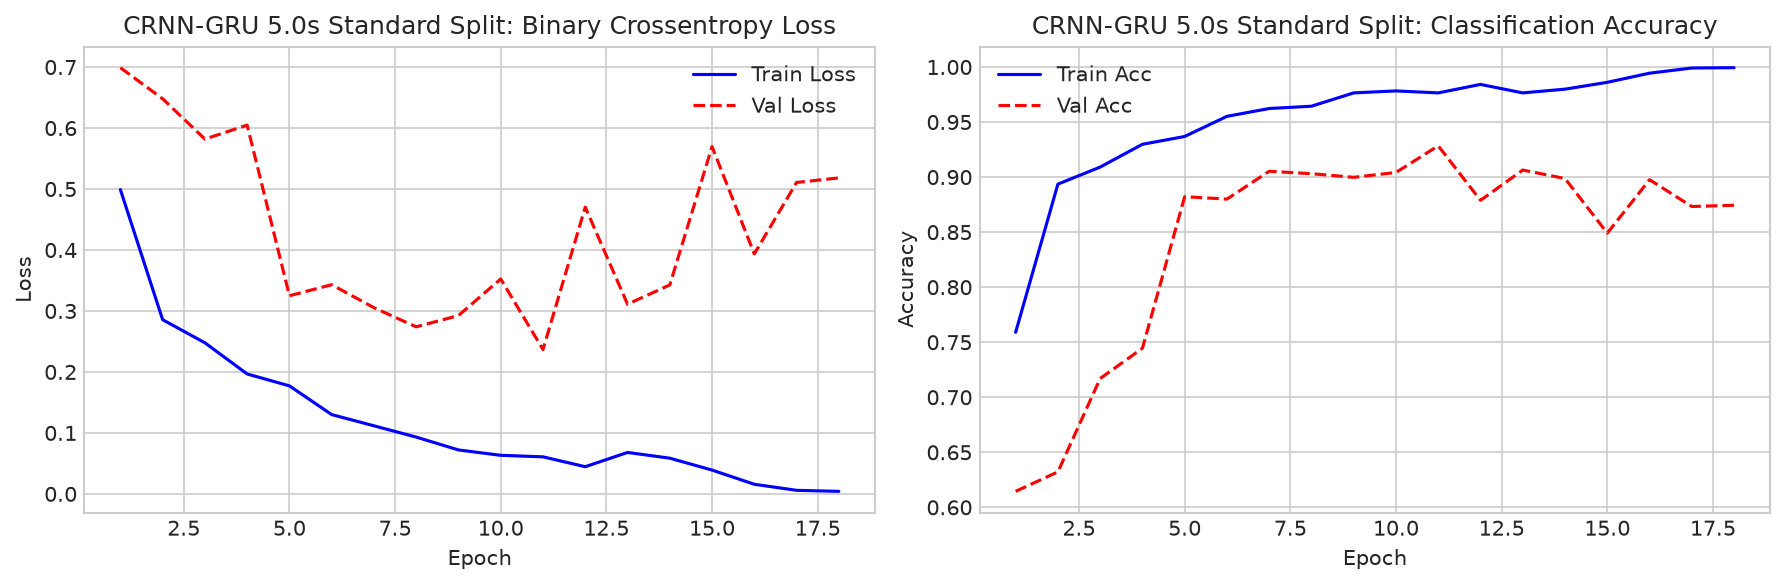

In [7]:
# Visualize training curves (5.0s Standard Split)
history_fig_5s_std = HISTORY_DIR / f"{NOTEBOOK_ID}-5s-standard-split-training-history.png"
plot_training_history(history_5s_std, history_fig_5s_std, title_prefix="CRNN-GRU 5.0s Standard Split")

#### 4.1.3 FP32 Model Evaluation on Test Set (5.0s Standard Split)

I0000 00:00:1788971862.428563   84691 service.cc:153] XLA service 0x7f25e0140090 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1788971862.428579   84691 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1788971862.478619   84691 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1788971862.910881   84691 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1788971862.922333   84691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1828__.7
I0000 00:00:1788971863.820961   84774 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26', 9052 bytes spill stores, 9140 bytes spill loads



16/68 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

I0000 00:00:1788971872.023918   84691 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


66/68 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

I0000 00:00:1788971873.580854   84692 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3255__.7
I0000 00:00:1788971875.109558   84998 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26', 8724 bytes spill stores, 8728 bytes spill loads



68/68 ━━━━━━━━━━━━━━━━━━━━ 15s 67ms/step
EVALUATION RESULTS: 5.0s Standard Split (FP32)
Accuracy:    0.9088 (90.88%)
Precision:   0.8843 (88.43%)
Recall:      0.9054 (90.54%)
F1-Score:    0.8947 (89.47%)
Specificity: 0.9112 (91.12%)
ROC-AUC:     0.9575
              precision    recall  f1-score   support

No Eagle (0)       0.93      0.91      0.92      1228
   Eagle (1)       0.88      0.91      0.89       920

    accuracy                           0.91      2148
   macro avg       0.91      0.91      0.91      2148
weighted avg       0.91      0.91      0.91      2148

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/confusion-matrices/04-crnn-gru-model-training-5s-standard-split-confusion-matrix.png


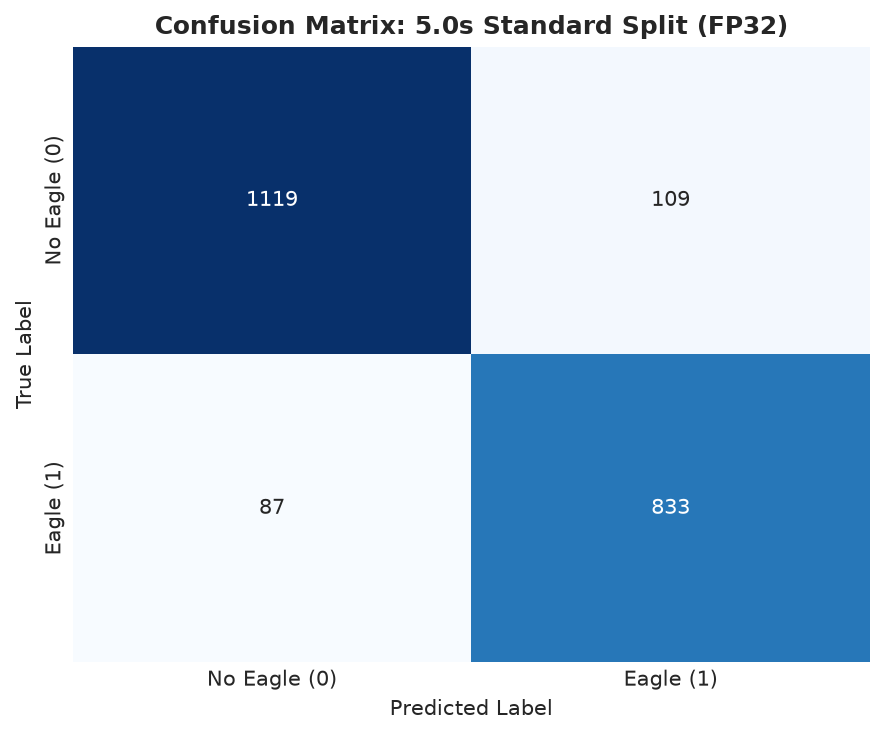

In [8]:
# Evaluate FP32 model on test set (5.0s Standard Split)
y_pred_prob_5s_std = model_5s_std.predict(X_test_5s, batch_size=BATCH_SIZE).ravel()
cm_fig_5s_std = CONFUSION_DIR / f"{NOTEBOOK_ID}-5s-standard-split-confusion-matrix.png"
metrics_5s_std = evaluate_predictions(y_test_5s, y_pred_prob_5s_std, "5.0s Standard Split (FP32)", cm_fig_5s_std)

#### 4.1.4 INT8 Quantization and Edge Benchmark (5.0s Standard Split)

In [9]:
# Full INT8 post-training quantization and benchmark (5.0s Standard Split, Guarded)
tflite_5s_std_path = MODELS_5S_STD / "crnn-gru-standard-int8.tflite"

if not tflite_5s_std_path.exists():
    print("Converting model to INT8 TFLite...")
    convert_to_tflite_int8(model_5s_std, X_train_5s[:300], tflite_5s_std_path)
    print(f"Saved INT8 TFLite model to: {tflite_5s_std_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_5s_std_path}")

int8_res_5s_std = evaluate_tflite_model(tflite_5s_std_path, X_test_5s, y_test_5s)
fp32_size_kb = os.path.getsize(model_5s_std_path) / 1024
int8_size_kb = int8_res_5s_std["model_size_kb"]

print("=" * 60)
print("5.0s STANDARD SPLIT: FP32 vs. INT8 BENCHMARK")
print("=" * 60)
print(f"FP32 Model Size:       {fp32_size_kb:.1f} KB")
print(f"INT8 Model Size:       {int8_size_kb:.1f} KB ({fp32_size_kb / int8_size_kb:.1f}x compression)")
print(f"INT8 Latency / sample: {int8_res_5s_std['inference_time_ms_per_sample']:.2f} ms")
print(f"FP32 Test Accuracy:    {metrics_5s_std['accuracy']*100:.2f}% | F1: {metrics_5s_std['f1_score']*100:.2f}%")
print(f"INT8 Test Accuracy:    {int8_res_5s_std['accuracy']*100:.2f}% | F1: {int8_res_5s_std['f1_score']*100:.2f}%")
print("=" * 60)

Loading cached INT8 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/5-seconds/standard-split/crnn-gru-standard-int8.tflite


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


5.0s STANDARD SPLIT: FP32 vs. INT8 BENCHMARK
FP32 Model Size:       3649.7 KB
INT8 Model Size:       626.1 KB (5.8x compression)
INT8 Latency / sample: 3.27 ms
FP32 Test Accuracy:    90.88% | F1: 89.47%
INT8 Test Accuracy:    89.53% | F1: 87.51%


### 4.2. Experiment 2: Leave-One-Site-Out (LOSO) - Davao del Sur (5.0s)

In [10]:
# 5.0s LOSO Davao del Sur: Hold out entire Davao del Sur site
HOLDOUT_SITE_1 = "Davao del Sur"
is_test_davao = (sites_all_5s == HOLDOUT_SITE_1)
is_train_pool_davao = ~is_test_davao

X_test_davao_5s = X_all_5s[is_test_davao]
y_test_davao_5s = y_all_5s[is_test_davao]

X_train_pool_davao = X_all_5s[is_train_pool_davao]
y_train_pool_davao = y_all_5s[is_train_pool_davao]
groups_train_pool_davao = groups_all_5s[is_train_pool_davao]

gss_davao = GroupShuffleSplit(n_splits=1, train_size=0.85, random_state=SEED)
tr_d_idx, val_d_idx = next(gss_davao.split(X_train_pool_davao, y_train_pool_davao, groups_train_pool_davao))

X_train_davao_5s = X_train_pool_davao[tr_d_idx]
y_train_davao_5s = y_train_pool_davao[tr_d_idx]
X_val_davao_5s = X_train_pool_davao[val_d_idx]
y_val_davao_5s = y_train_pool_davao[val_d_idx]

print(f"5.0s LOSO Davao del Sur Partition:")
print(f"Train: {len(X_train_davao_5s):,} | Val: {len(X_val_davao_5s):,} | Test (Davao del Sur): {len(X_test_davao_5s):,}")

5.0s LOSO Davao del Sur Partition:
Train: 2,503 | Val: 167 | Test (Davao del Sur): 3,619


#### 4.2.1 Train or Load Model (5.0s LOSO Davao)

In [11]:
# Train or load 5.0s LOSO Davao del Sur model (Guarded)
model_5s_davao_path = MODELS_5S_DAVAO / "crnn-gru-loso-davao.keras"
history_5s_davao_path = MODELS_5S_DAVAO / "training_history.json"

class_weights_davao_5s = compute_class_weights(y_train_davao_5s)
print(f"Balanced Class Weights (LOSO Davao): {class_weights_davao_5s}")

if model_5s_davao_path.exists():
    print(f"Model already exists at: {model_5s_davao_path}")
    print("Loading cached model...")
    model_5s_davao = tf.keras.models.load_model(model_5s_davao_path)
    with open(history_5s_davao_path, "r") as f:
        history_5s_davao = json.load(f)
    print("Model loaded successfully from cache!")
else:
    print("Training 5.0s LOSO Davao model...")
    model_5s_davao = build_crnn_gru_model(input_shape=SHAPE_5S, learning_rate=LEARNING_RATE)
    callbacks_d = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_5S_DAVAO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]
    fit_d = model_5s_davao.fit(
        X_train_davao_5s, y_train_davao_5s,
        validation_data=(X_val_davao_5s, y_val_davao_5s),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        class_weight=class_weights_davao_5s,
        callbacks=callbacks_d, verbose=1
    )
    model_5s_davao.save(model_5s_davao_path)
    history_5s_davao = {k: [float(v) for v in vals] for k, vals in fit_d.history.items()}
    with open(history_5s_davao_path, "w") as f:
        json.dump(history_5s_davao, f)

Balanced Class Weights (LOSO Davao): {0: 1.004414125200642, 1: 0.9956245027844074}
Model already exists at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/5-seconds/loso-davao/crnn-gru-loso-davao.keras
Loading cached model...
Model loaded successfully from cache!


#### 4.2.2 Training History Visualization (5.0s LOSO Davao)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/training-history/04-crnn-gru-model-training-5s-loso-davao-training-history.png


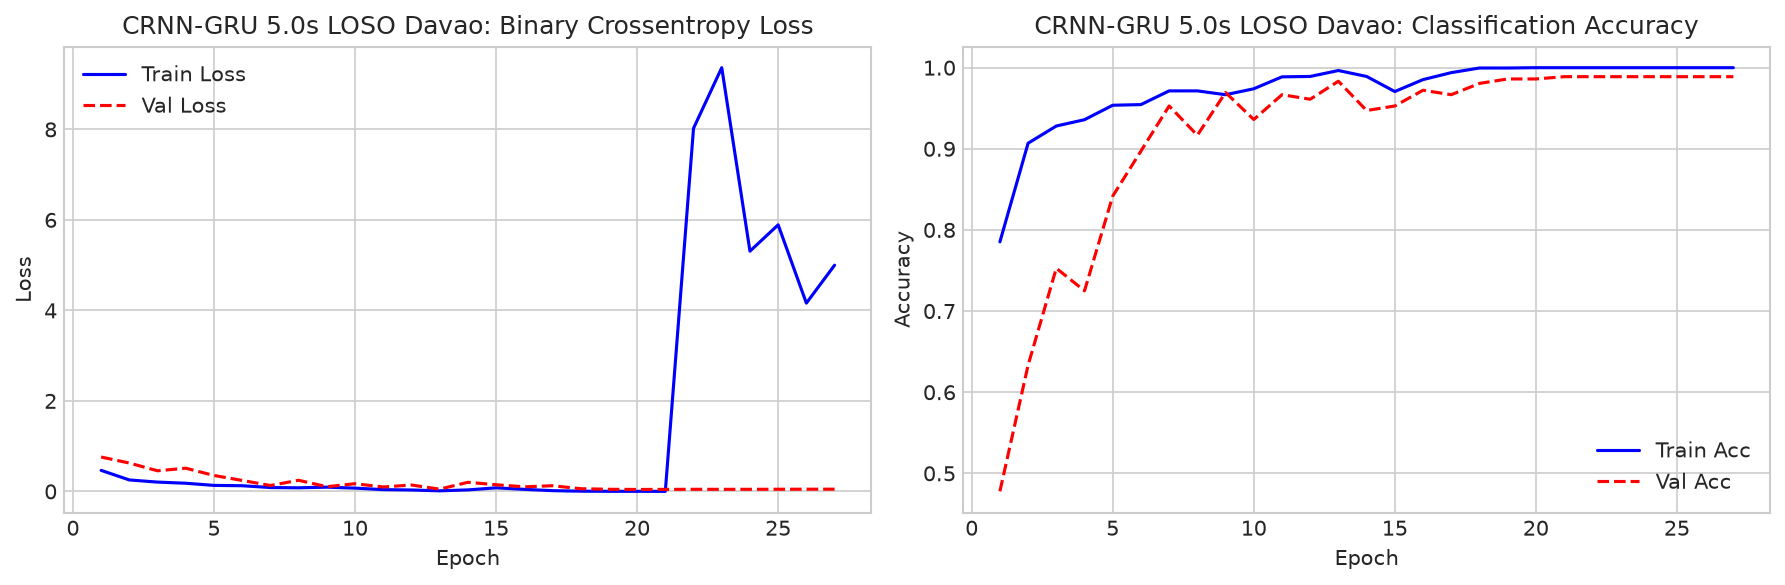

In [12]:
# Visualize training curves (5.0s LOSO Davao)
history_fig_5s_davao = HISTORY_DIR / f"{NOTEBOOK_ID}-5s-loso-davao-training-history.png"
plot_training_history(history_5s_davao, history_fig_5s_davao, title_prefix="CRNN-GRU 5.0s LOSO Davao")

#### 4.2.3 FP32 Model Evaluation (5.0s LOSO Davao)

I0000 00:00:1788971886.638888   84693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5490__.7


113/114 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

I0000 00:00:1788971890.675361   84693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7009__.7
I0000 00:00:1788971892.180599   85239 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26', 9460 bytes spill stores, 9568 bytes spill loads



114/114 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step
EVALUATION RESULTS: 5.0s LOSO Davao del Sur (FP32)
Accuracy:    0.8497 (84.97%)
Precision:   0.8594 (85.94%)
Recall:      0.7635 (76.35%)
F1-Score:    0.8086 (80.86%)
Specificity: 0.9111 (91.11%)
ROC-AUC:     0.9038
              precision    recall  f1-score   support

No Eagle (0)       0.84      0.91      0.88      2114
   Eagle (1)       0.86      0.76      0.81      1505

    accuracy                           0.85      3619
   macro avg       0.85      0.84      0.84      3619
weighted avg       0.85      0.85      0.85      3619

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/confusion-matrices/04-crnn-gru-model-training-5s-loso-davao-confusion-matrix.png


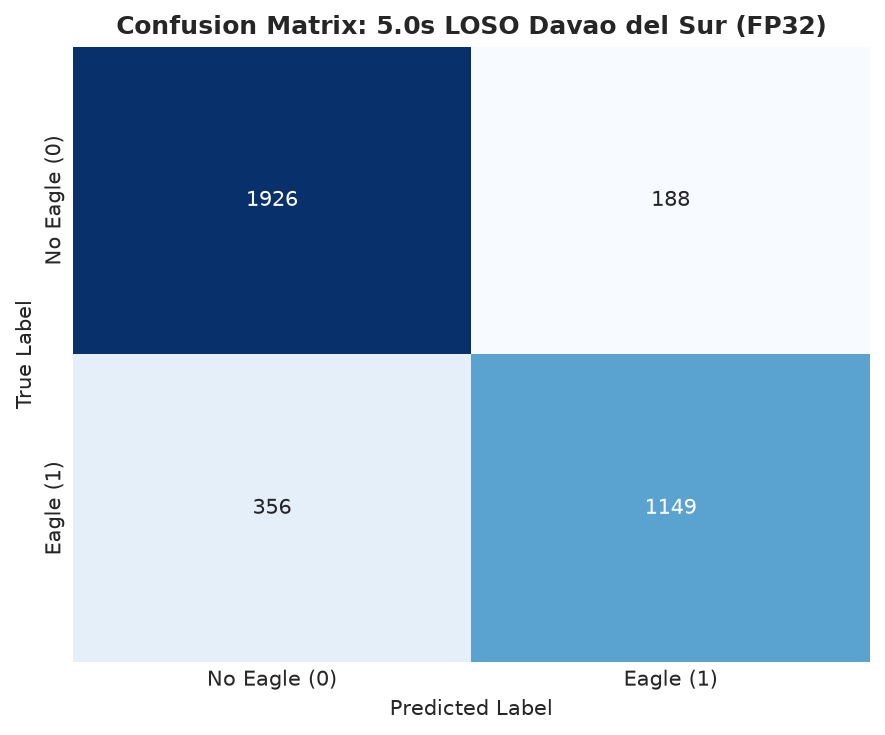

In [13]:
# Evaluate FP32 model on Davao del Sur test set
y_pred_prob_davao_5s = model_5s_davao.predict(X_test_davao_5s, batch_size=BATCH_SIZE).ravel()
cm_fig_5s_davao = CONFUSION_DIR / f"{NOTEBOOK_ID}-5s-loso-davao-confusion-matrix.png"
metrics_5s_davao = evaluate_predictions(y_test_davao_5s, y_pred_prob_davao_5s, "5.0s LOSO Davao del Sur (FP32)", cm_fig_5s_davao)

#### 4.2.4 INT8 Quantization and Benchmark (5.0s LOSO Davao)

In [14]:
# Full INT8 post-training quantization and benchmark (5.0s LOSO Davao, Guarded)
tflite_5s_davao_path = MODELS_5S_DAVAO / "crnn-gru-loso-davao-int8.tflite"

if not tflite_5s_davao_path.exists():
    print("Converting model to INT8 TFLite...")
    convert_to_tflite_int8(model_5s_davao, X_train_davao_5s[:300], tflite_5s_davao_path)
    print(f"Saved INT8 TFLite model to: {tflite_5s_davao_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_5s_davao_path}")

int8_res_5s_davao = evaluate_tflite_model(tflite_5s_davao_path, X_test_davao_5s, y_test_davao_5s)
print(f"5.0s LOSO Davao del Sur INT8 Accuracy: {int8_res_5s_davao['accuracy']*100:.2f}% | F1: {int8_res_5s_davao['f1_score']*100:.2f}%")

Loading cached INT8 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/5-seconds/loso-davao/crnn-gru-loso-davao-int8.tflite
5.0s LOSO Davao del Sur INT8 Accuracy: 82.81% | F1: 79.49%


### 4.3. Experiment 3: Leave-One-Site-Out (LOSO) - Cotabato (5.0s)

In [15]:
# 5.0s LOSO Cotabato: Hold out entire Cotabato site
HOLDOUT_SITE_2 = "Cotabato"
is_test_cot = (sites_all_5s == HOLDOUT_SITE_2)
is_train_pool_cot = ~is_test_cot

X_test_cot_5s = X_all_5s[is_test_cot]
y_test_cot_5s = y_all_5s[is_test_cot]

X_train_pool_cot = X_all_5s[is_train_pool_cot]
y_train_pool_cot = y_all_5s[is_train_pool_cot]
groups_train_pool_cot = groups_all_5s[is_train_pool_cot]

gss_cot = GroupShuffleSplit(n_splits=1, train_size=0.85, random_state=SEED)
tr_c_idx, val_c_idx = next(gss_cot.split(X_train_pool_cot, y_train_pool_cot, groups_train_pool_cot))

X_train_cot_5s = X_train_pool_cot[tr_c_idx]
y_train_cot_5s = y_train_pool_cot[tr_c_idx]
X_val_cot_5s = X_train_pool_cot[val_c_idx]
y_val_cot_5s = y_train_pool_cot[val_c_idx]

print(f"5.0s LOSO Cotabato Partition:")
print(f"Train: {len(X_train_cot_5s):,} | Val: {len(X_val_cot_5s):,} | Test (Cotabato): {len(X_test_cot_5s):,}")

5.0s LOSO Cotabato Partition:
Train: 3,559 | Val: 238 | Test (Cotabato): 2,492


#### 4.3.1 Train or Load Model (5.0s LOSO Cotabato)

In [16]:
# Train or load 5.0s LOSO Cotabato model (Guarded)
model_5s_cot_path = MODELS_5S_COTABATO / "crnn-gru-loso-cotabato.keras"
history_5s_cot_path = MODELS_5S_COTABATO / "training_history.json"

class_weights_cot_5s = compute_class_weights(y_train_cot_5s)
print(f"Balanced Class Weights (LOSO Cotabato): {class_weights_cot_5s}")

if model_5s_cot_path.exists():
    print(f"Model already exists at: {model_5s_cot_path}")
    print("Loading cached model...")
    model_5s_cot = tf.keras.models.load_model(model_5s_cot_path)
    with open(history_5s_cot_path, "r") as f:
        history_5s_cot = json.load(f)
    print("Model loaded successfully from cache!")
else:
    print("Training 5.0s LOSO Cotabato model...")
    model_5s_cot = build_crnn_gru_model(input_shape=SHAPE_5S, learning_rate=LEARNING_RATE)
    callbacks_c = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(MODELS_5S_COTABATO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
    ]
    fit_c = model_5s_cot.fit(
        X_train_cot_5s, y_train_cot_5s,
        validation_data=(X_val_cot_5s, y_val_cot_5s),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        class_weight=class_weights_cot_5s,
        callbacks=callbacks_c, verbose=1
    )
    model_5s_cot.save(model_5s_cot_path)
    history_5s_cot = {k: [float(v) for v in vals] for k, vals in fit_c.history.items()}
    with open(history_5s_cot_path, "w") as f:
        json.dump(history_5s_cot, f)

Balanced Class Weights (LOSO Cotabato): {0: 0.8584177520501689, 1: 1.1975100942126515}
Model already exists at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/5-seconds/loso-cotabato/crnn-gru-loso-cotabato.keras
Loading cached model...
Model loaded successfully from cache!


#### 4.3.2 Training History Visualization (5.0s LOSO Cotabato)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/training-history/04-crnn-gru-model-training-5s-loso-cotabato-training-history.png


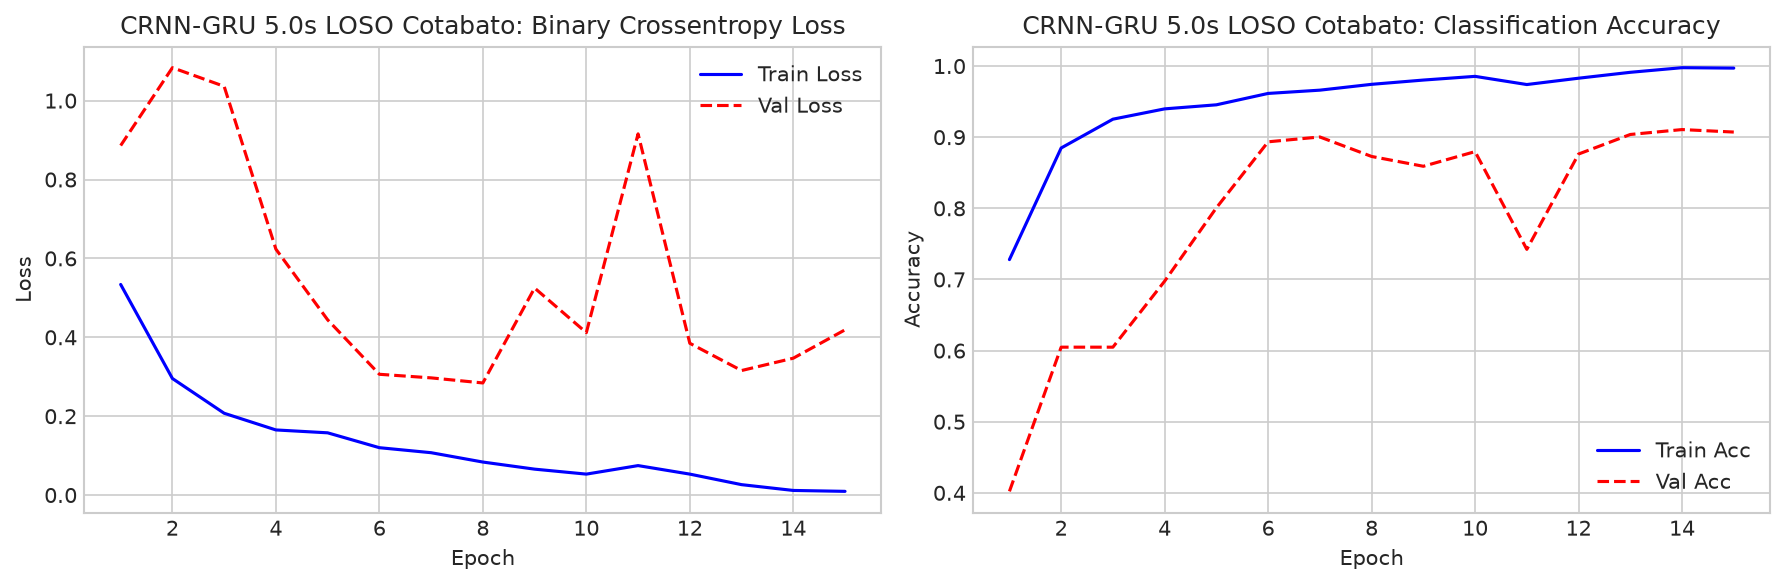

In [17]:
# Visualize training curves (5.0s LOSO Cotabato)
history_fig_5s_cot = HISTORY_DIR / f"{NOTEBOOK_ID}-5s-loso-cotabato-training-history.png"
plot_training_history(history_5s_cot, history_fig_5s_cot, title_prefix="CRNN-GRU 5.0s LOSO Cotabato")

#### 4.3.3 FP32 Model Evaluation (5.0s LOSO Cotabato)

I0000 00:00:1788971910.191919   84691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_9474__.7


76/78 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

I0000 00:00:1788971914.636129   84691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_10921__.7
I0000 00:00:1788971915.718357   85518 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26', 9300 bytes spill stores, 9324 bytes spill loads



78/78 ━━━━━━━━━━━━━━━━━━━━ 15s 148ms/step
EVALUATION RESULTS: 5.0s LOSO Cotabato (FP32)
Accuracy:    0.8030 (80.30%)
Precision:   0.7272 (72.72%)
Recall:      0.9530 (95.30%)
F1-Score:    0.8250 (82.50%)
Specificity: 0.6604 (66.04%)
ROC-AUC:     0.9395
              precision    recall  f1-score   support

No Eagle (0)       0.94      0.66      0.77      1278
   Eagle (1)       0.73      0.95      0.82      1214

    accuracy                           0.80      2492
   macro avg       0.83      0.81      0.80      2492
weighted avg       0.83      0.80      0.80      2492

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/confusion-matrices/04-crnn-gru-model-training-5s-loso-cotabato-confusion-matrix.png


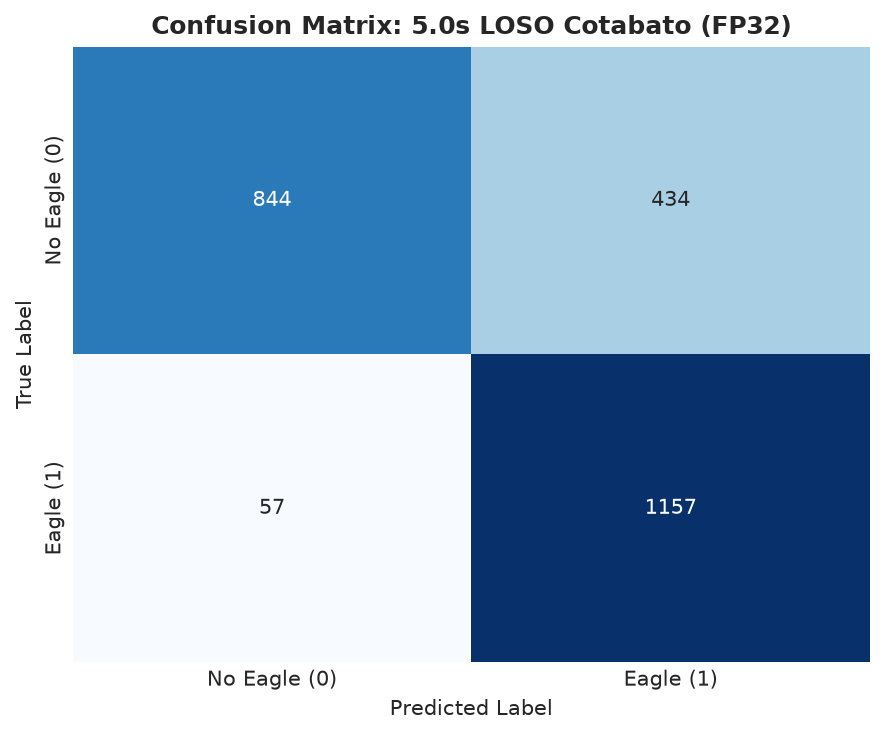

In [18]:
# Evaluate FP32 model on Cotabato test set
y_pred_prob_cot_5s = model_5s_cot.predict(X_test_cot_5s, batch_size=BATCH_SIZE).ravel()
cm_fig_5s_cot = CONFUSION_DIR / f"{NOTEBOOK_ID}-5s-loso-cotabato-confusion-matrix.png"
metrics_5s_cot = evaluate_predictions(y_test_cot_5s, y_pred_prob_cot_5s, "5.0s LOSO Cotabato (FP32)", cm_fig_5s_cot)

#### 4.3.4 INT8 Quantization and Benchmark (5.0s LOSO Cotabato)

In [19]:
# Full INT8 post-training quantization and benchmark (5.0s LOSO Cotabato, Guarded)
tflite_5s_cot_path = MODELS_5S_COTABATO / "crnn-gru-loso-cotabato-int8.tflite"

if not tflite_5s_cot_path.exists():
    print("Converting model to INT8 TFLite...")
    convert_to_tflite_int8(model_5s_cot, X_train_cot_5s[:300], tflite_5s_cot_path)
    print(f"Saved INT8 TFLite model to: {tflite_5s_cot_path}")
else:
    print(f"Loading cached INT8 model from: {tflite_5s_cot_path}")

int8_res_5s_cot = evaluate_tflite_model(tflite_5s_cot_path, X_test_cot_5s, y_test_cot_5s)
print(f"5.0s LOSO Cotabato INT8 Accuracy: {int8_res_5s_cot['accuracy']*100:.2f}% | F1: {int8_res_5s_cot['f1_score']*100:.2f}%")

Loading cached INT8 model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/5-seconds/loso-cotabato/crnn-gru-loso-cotabato-int8.tflite
5.0s LOSO Cotabato INT8 Accuracy: 85.63% | F1: 83.50%


## 5. 3.0-Second CRNN-GRU Experiments (128, 130)

### 5.1. Experiment 1: Standard Split (3.0s)

In [20]:
# 3.0s Standard Split: GroupShuffleSplit (70% Train, 15% Val, 15% Test)
if X_all_3s is not None:
    gss_outer_3s = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
    train_idx_3s, temp_idx_3s = next(gss_outer_3s.split(X_all_3s, y_all_3s, groups_all_3s))

    X_train_3s, y_train_3s = X_all_3s[train_idx_3s], y_all_3s[train_idx_3s]
    groups_train_3s = groups_all_3s[train_idx_3s]

    X_temp_3s, y_temp_3s = X_all_3s[temp_idx_3s], y_all_3s[temp_idx_3s]
    groups_temp_3s = groups_all_3s[temp_idx_3s]

    gss_inner_3s = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    val_sub_idx_3s, test_sub_idx_3s = next(gss_inner_3s.split(X_temp_3s, y_temp_3s, groups_temp_3s))

    X_val_3s, y_val_3s = X_temp_3s[val_sub_idx_3s], y_temp_3s[val_sub_idx_3s]
    X_test_3s, y_test_3s = X_temp_3s[test_sub_idx_3s], y_temp_3s[test_sub_idx_3s]

    print("3.0s Standard Split Partition:")
    print(f"Train samples: {len(X_train_3s):,} ({len(np.unique(groups_train_3s))} unique audio sources)")
    print(f"Val samples:   {len(X_val_3s):,} ({len(np.unique(groups_temp_3s[val_sub_idx_3s]))} unique audio sources)")
    print(f"Test samples:  {len(X_test_3s):,} ({len(np.unique(groups_temp_3s[test_sub_idx_3s]))} unique audio sources)")
else:
    print("3.0s features not loaded. Skipping 3.0s standard split.")

3.0s Standard Split Partition:
Train samples: 4,411 (41 unique audio sources)
Val samples:   1,229 (9 unique audio sources)
Test samples:  2,959 (9 unique audio sources)


#### 5.1.1 Train or Load Model (3.0s Standard Split)

In [21]:
# Train or load 3.0s Standard Split model (Guarded, with Balanced Class Weights)
if X_all_3s is not None:
    model_3s_std_path = MODELS_3S_STD / "crnn-gru-standard.keras"
    history_3s_std_path = MODELS_3S_STD / "training_history.json"

    class_weights_3s_std = compute_class_weights(y_train_3s)
    print(f"Balanced Class Weights (3s Standard): {class_weights_3s_std}")

    if model_3s_std_path.exists():
        print(f"Model already exists at: {model_3s_std_path}")
        print("Loading cached model...")
        model_3s_std = tf.keras.models.load_model(model_3s_std_path)
        with open(history_3s_std_path, "r") as f:
            history_3s_std = json.load(f)
        print("3.0s Standard model loaded successfully from cache!")
    else:
        print("Training 3.0s Standard Split CRNN-GRU model...")
        model_3s_std = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=LEARNING_RATE)

        callbacks_3s = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_STD / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
        ]

        fit_3s = model_3s_std.fit(
            X_train_3s, y_train_3s,
            validation_data=(X_val_3s, y_val_3s),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            class_weight=class_weights_3s_std,
            callbacks=callbacks_3s, verbose=1
        )
        model_3s_std.save(model_3s_std_path)
        history_3s_std = {k: [float(v) for v in vals] for k, vals in fit_3s.history.items()}
        with open(history_3s_std_path, "w") as f:
            json.dump(history_3s_std, f)
        print(f"Saved trained 3.0s model to: {model_3s_std_path}")
else:
    model_3s_std = None

Balanced Class Weights (3s Standard): {0: 0.8676239181746657, 1: 1.1800428036383093}
Training 3.0s Standard Split CRNN-GRU model...
Epoch 1/40


I0000 00:00:1788971940.721946   84691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_20393__.95
I0000 00:00:1788971942.017709   85846 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 8652 bytes spill stores, 8640 bytes spill loads

I0000 00:00:1788971942.822657   84691 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1788971944.126081   84691 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


137/138 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8228 - auc: 0.8939 - loss: 0.4067 - precision: 0.7918 - recall: 0.7888

I0000 00:00:1788971968.131665   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_20393__.95
I0000 00:00:1788971970.467290   86365 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17', 8988 bytes spill stores, 9076 bytes spill loads



138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.8227 - auc: 0.8941 - loss: 0.4065 - precision: 0.7917 - recall: 0.7892

I0000 00:00:1788971987.099526   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22767__.23
I0000 00:00:1788971993.708981   84693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22767__.23
I0000 00:00:1788971995.723957   86975 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 9468 bytes spill stores, 9408 bytes spill loads



138/138 ━━━━━━━━━━━━━━━━━━━━ 64s 274ms/step - accuracy: 0.8227 - auc: 0.8941 - loss: 0.4065 - precision: 0.7917 - recall: 0.7892 - val_accuracy: 0.3426 - val_auc: 0.7056 - val_loss: 0.8196 - val_precision: 0.3331 - val_recall: 0.9926
Epoch 2/40
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9032 - auc: 0.9490 - loss: 0.2762 - precision: 0.8885 - recall: 0.8823 - val_accuracy: 0.8324 - val_auc: 0.8505 - val_loss: 0.4458 - val_precision: 0.9462 - val_recall: 0.5210
Epoch 3/40
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9139 - auc: 0.9632 - loss: 0.2366 - precision: 0.8945 - recall: 0.9032 - val_accuracy: 0.8763 - val_auc: 0.9359 - val_loss: 0.3074 - val_precision: 0.7935 - val_recall: 0.8444
Epoch 4/40
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9275 - auc: 0.9722 - loss: 0.2037 - precision: 0.9148 - recall: 0.9139 - val_accuracy: 0.9186 - val_auc: 0.9590 - val_loss: 0.2414 - val_precision: 0.8941 - val_recall: 0.8543
Epoch 5/40
138/138 ━━━━━━━━━━━━━━━━━━

#### 5.1.2 Training History Visualization (3.0s Standard Split)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/training-history/04-crnn-gru-model-training-3s-standard-split-training-history.png


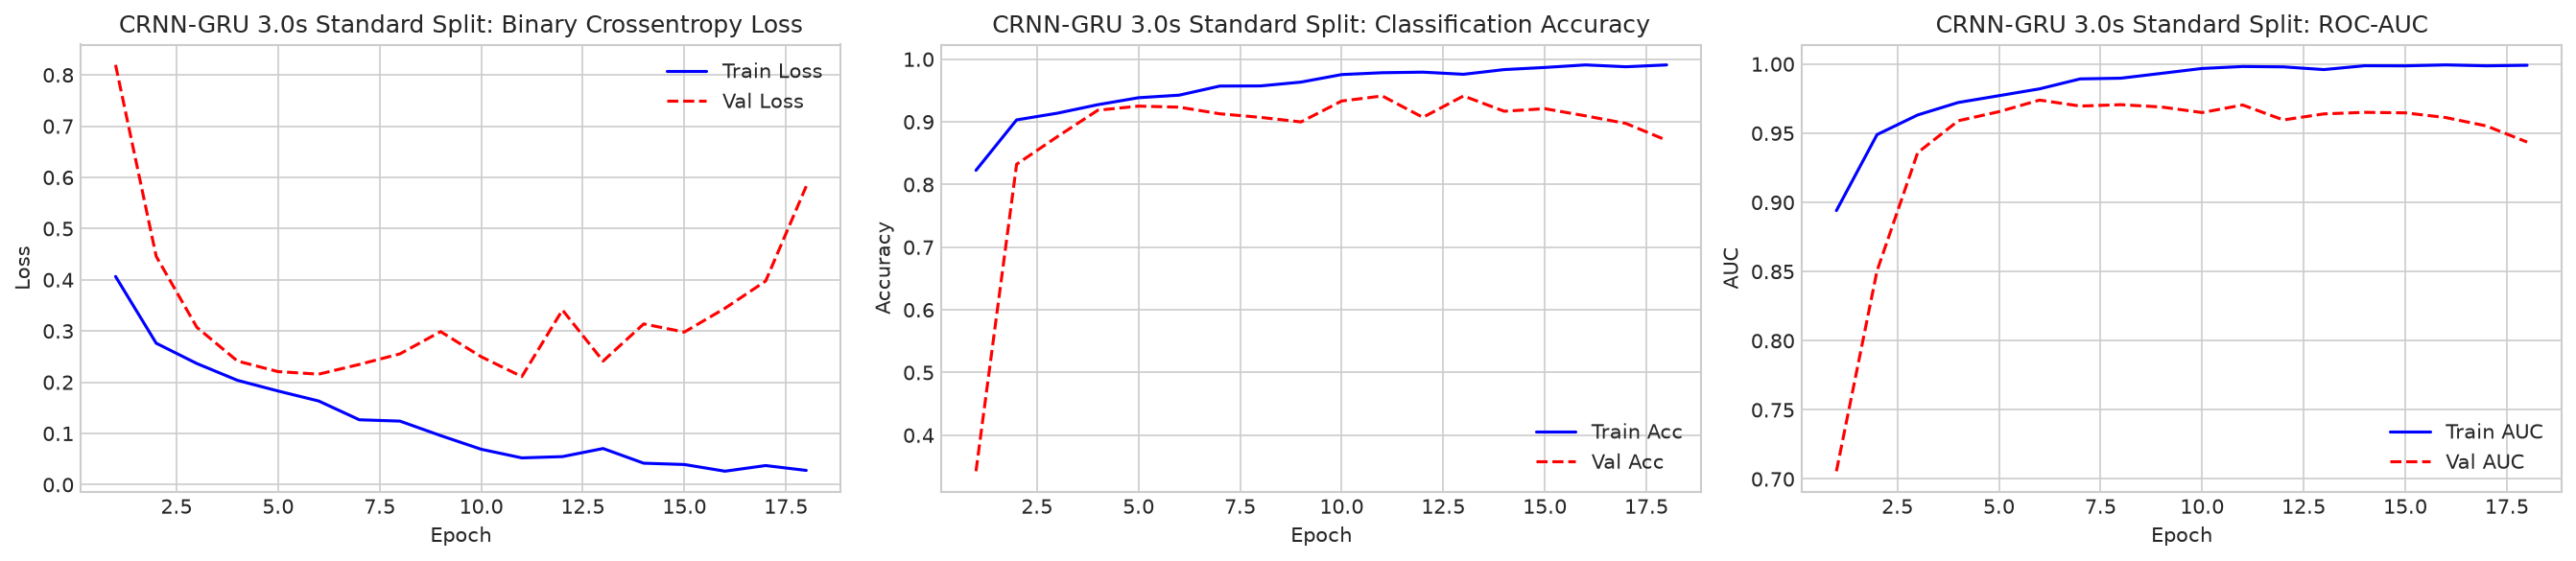

In [22]:
# Visualize training curves (3.0s Standard Split)
if model_3s_std is not None and history_3s_std_path.exists():
    history_fig_3s_std = HISTORY_DIR / f"{NOTEBOOK_ID}-3s-standard-split-training-history.png"
    plot_training_history(history_3s_std, history_fig_3s_std, title_prefix="CRNN-GRU 3.0s Standard Split")

#### 5.1.3 FP32 Model Evaluation on Test Set (3.0s Standard Split)

I0000 00:00:1788972085.629822   84691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_49669__.7


92/93 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

I0000 00:00:1788972088.057043   84689 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50695__.7
I0000 00:00:1788972089.538539   89453 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 9168 bytes spill stores, 9268 bytes spill loads



93/93 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step
EVALUATION RESULTS: 3.0s Standard Split (FP32)
Accuracy:    0.9108 (91.08%)
Precision:   0.9056 (90.56%)
Recall:      0.8391 (83.91%)
F1-Score:    0.8711 (87.11%)
Specificity: 0.9509 (95.09%)
ROC-AUC:     0.9519
              precision    recall  f1-score   support

No Eagle (0)       0.91      0.95      0.93      1896
   Eagle (1)       0.91      0.84      0.87      1063

    accuracy                           0.91      2959
   macro avg       0.91      0.90      0.90      2959
weighted avg       0.91      0.91      0.91      2959

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/confusion-matrices/04-crnn-gru-model-training-3s-standard-split-confusion-matrix.png


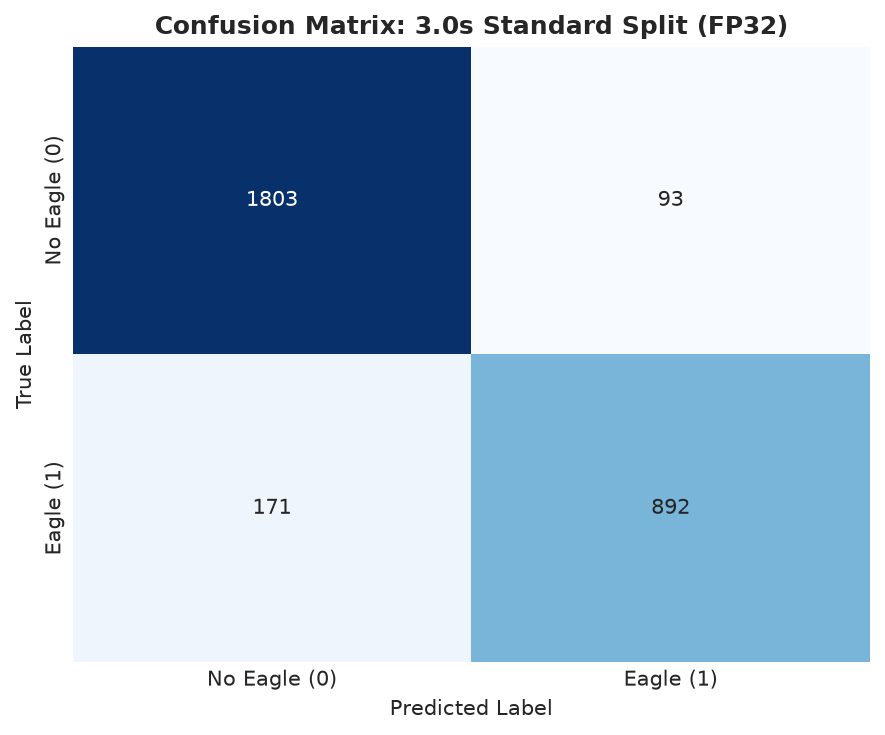

In [23]:
# Evaluate FP32 model on test set (3.0s Standard Split)
if model_3s_std is not None:
    y_pred_prob_3s_std = model_3s_std.predict(X_test_3s, batch_size=BATCH_SIZE).ravel()
    cm_fig_3s_std = CONFUSION_DIR / f"{NOTEBOOK_ID}-3s-standard-split-confusion-matrix.png"
    metrics_3s_std = evaluate_predictions(y_test_3s, y_pred_prob_3s_std, "3.0s Standard Split (FP32)", cm_fig_3s_std)
else:
    metrics_3s_std = None

#### 5.1.4 INT8 Quantization and Edge Benchmark (3.0s Standard Split)

In [24]:
# Full INT8 post-training quantization and benchmark (3.0s Standard Split, Guarded)
if model_3s_std is not None:
    tflite_3s_std_path = MODELS_3S_STD / "crnn-gru-standard-int8.tflite"
    if not tflite_3s_std_path.exists():
        print("Converting 3.0s model to INT8 TFLite...")
        convert_to_tflite_int8(model_3s_std, X_train_3s[:300], tflite_3s_std_path)
        print(f"Saved INT8 TFLite model to: {tflite_3s_std_path}")
    else:
        print(f"Loading cached 3.0s INT8 model from: {tflite_3s_std_path}")

    int8_res_3s_std = evaluate_tflite_model(tflite_3s_std_path, X_test_3s, y_test_3s)
    fp32_size_3s_kb = os.path.getsize(model_3s_std_path) / 1024
    int8_size_3s_kb = int8_res_3s_std["model_size_kb"]

    print("=" * 60)
    print("3.0s STANDARD SPLIT: FP32 vs. INT8 BENCHMARK")
    print("=" * 60)
    print(f"FP32 Model Size:       {fp32_size_3s_kb:.1f} KB")
    print(f"INT8 Model Size:       {int8_size_3s_kb:.1f} KB ({fp32_size_3s_kb / int8_size_3s_kb:.1f}x compression)")
    print(f"INT8 Latency / sample: {int8_res_3s_std['inference_time_ms_per_sample']:.2f} ms")
    print(f"FP32 Test Accuracy:    {metrics_3s_std['accuracy']*100:.2f}% | F1: {metrics_3s_std['f1_score']*100:.2f}%")
    print(f"INT8 Test Accuracy:    {int8_res_3s_std['accuracy']*100:.2f}% | F1: {int8_res_3s_std['f1_score']*100:.2f}%")
    print("=" * 60)
else:
    int8_res_3s_std = None

Converting 3.0s model to INT8 TFLite...
INFO:tensorflow:Assets written to: /tmp/tmpnczijmd9/assets


INFO:tensorflow:Assets written to: /tmp/tmpnczijmd9/assets


Saved artifact at '/tmp/tmpnczijmd9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 130, 1), dtype=tf.float32, name='audio_input')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139792641883216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641878992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641881296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641874384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641882640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641880720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641878416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641877072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614631824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614631440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792641876304

W0000 00:00:1788972094.312187   84588 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1788972094.312204   84588 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1788972094.312455   84588 reader.cc:83] Reading SavedModel from: /tmp/tmpnczijmd9
I0000 00:00:1788972094.313516   84588 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1788972094.313522   84588 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpnczijmd9
I0000 00:00:1788972094.327149   84588 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1788972094.328559   84588 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1788972094.391752   84588 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpnczijmd9
I0000 00:00:1788972094.417108   84588 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 104659 microseconds.
fully_quantize: 0, inference_type: 6

Saved INT8 TFLite model to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/3-seconds/standard-split/crnn-gru-standard-int8.tflite
3.0s STANDARD SPLIT: FP32 vs. INT8 BENCHMARK
FP32 Model Size:       3649.7 KB
INT8 Model Size:       498.5 KB (7.3x compression)
INT8 Latency / sample: 1.94 ms
FP32 Test Accuracy:    91.08% | F1: 87.11%
INT8 Test Accuracy:    88.85% | F1: 82.50%


### 5.2. Experiment 2: Leave-One-Site-Out (LOSO) - Davao del Sur (3.0s)

In [25]:
# 3.0s LOSO Davao del Sur: Hold out entire Davao del Sur site
if X_all_3s is not None:
    is_test_davao_3s = (sites_all_3s == HOLDOUT_SITE_1)
    is_train_pool_davao_3s = ~is_test_davao_3s

    X_test_davao_3s = X_all_3s[is_test_davao_3s]
    y_test_davao_3s = y_all_3s[is_test_davao_3s]

    X_train_pool_davao_3s = X_all_3s[is_train_pool_davao_3s]
    y_train_pool_davao_3s = y_all_3s[is_train_pool_davao_3s]
    groups_train_pool_davao_3s = groups_all_3s[is_train_pool_davao_3s]

    gss_davao_3s = GroupShuffleSplit(n_splits=1, train_size=0.85, random_state=SEED)
    tr_d3_idx, val_d3_idx = next(gss_davao_3s.split(X_train_pool_davao_3s, y_train_pool_davao_3s, groups_train_pool_davao_3s))

    X_train_davao_3s = X_train_pool_davao_3s[tr_d3_idx]
    y_train_davao_3s = y_train_pool_davao_3s[tr_d3_idx]
    X_val_davao_3s = X_train_pool_davao_3s[val_d3_idx]
    y_val_davao_3s = y_train_pool_davao_3s[val_d3_idx]

    print(f"3.0s LOSO Davao del Sur Partition:")
    print(f"Train: {len(X_train_davao_3s):,} | Val: {len(X_val_davao_3s):,} | Test (Davao del Sur): {len(X_test_davao_3s):,}")
else:
    print("3.0s features not loaded.")

3.0s LOSO Davao del Sur Partition:
Train: 3,405 | Val: 237 | Test (Davao del Sur): 4,957


#### 5.2.1 Train or Load Model (3.0s LOSO Davao)

In [26]:
# Train or load 3.0s LOSO Davao del Sur model (Guarded, with Balanced Class Weights)
if X_all_3s is not None:
    model_3s_davao_path = MODELS_3S_DAVAO / "crnn-gru-loso-davao.keras"
    history_3s_davao_path = MODELS_3S_DAVAO / "training_history.json"

    class_weights_davao_3s = compute_class_weights(y_train_davao_3s)
    print(f"Balanced Class Weights (3s LOSO Davao): {class_weights_davao_3s}")

    if model_3s_davao_path.exists():
        print(f"Model already exists at: {model_3s_davao_path}")
        print("Loading cached model...")
        model_3s_davao = tf.keras.models.load_model(model_3s_davao_path)
        with open(history_3s_davao_path, "r") as f:
            history_3s_davao = json.load(f)
        print("3.0s LOSO Davao model loaded successfully from cache!")
    else:
        print("Training 3.0s LOSO Davao model...")
        model_3s_davao = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=LEARNING_RATE)
        callbacks_d3 = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_DAVAO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
        ]
        fit_d3 = model_3s_davao.fit(
            X_train_davao_3s, y_train_davao_3s,
            validation_data=(X_val_davao_3s, y_val_davao_3s),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            class_weight=class_weights_davao_3s,
            callbacks=callbacks_d3, verbose=1
        )
        model_3s_davao.save(model_3s_davao_path)
        history_3s_davao = {k: [float(v) for v in vals] for k, vals in fit_d3.history.items()}
        with open(history_3s_davao_path, "w") as f:
            json.dump(history_3s_davao, f)
else:
    model_3s_davao = None

Balanced Class Weights (3s LOSO Davao): {0: 0.908, 1: 1.1127450980392155}
Training 3.0s LOSO Davao model...
Epoch 1/40


I0000 00:00:1788972115.130225   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_65293__.95


106/107 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8104 - auc: 0.8928 - loss: 0.4129 - precision: 0.7927 - recall: 0.7817

I0000 00:00:1788972126.730247   84688 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_65293__.95


107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.8112 - auc: 0.8935 - loss: 0.4117 - precision: 0.7939 - recall: 0.7830

I0000 00:00:1788972141.308425   84688 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_67450__.23
I0000 00:00:1788972143.433515   84688 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_67450__.23


107/107 ━━━━━━━━━━━━━━━━━━━━ 35s 215ms/step - accuracy: 0.8112 - auc: 0.8935 - loss: 0.4117 - precision: 0.7939 - recall: 0.7830 - val_accuracy: 0.5612 - val_auc: 0.8282 - val_loss: 0.6671 - val_precision: 1.0000 - val_recall: 0.0957
Epoch 2/40
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9157 - auc: 0.9558 - loss: 0.2506 - precision: 0.9163 - recall: 0.8941 - val_accuracy: 0.6287 - val_auc: 0.9053 - val_loss: 0.5786 - val_precision: 0.5692 - val_recall: 0.9652
Epoch 3/40
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9292 - auc: 0.9687 - loss: 0.2106 - precision: 0.9277 - recall: 0.9137 - val_accuracy: 0.7384 - val_auc: 0.9370 - val_loss: 0.4148 - val_precision: 0.6646 - val_recall: 0.9304
Epoch 4/40
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9401 - auc: 0.9765 - loss: 0.1794 - precision: 0.9402 - recall: 0.9255 - val_accuracy: 0.8819 - val_auc: 0.9380 - val_loss: 0.3339 - val_precision: 0.9780 - val_recall: 0.7739
Epoch 5/40
107/107 ━━━━━━━━━━━━━━━━━━

#### 5.2.2 Training History Visualization (3.0s LOSO Davao)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/training-history/04-crnn-gru-model-training-3s-loso-davao-training-history.png


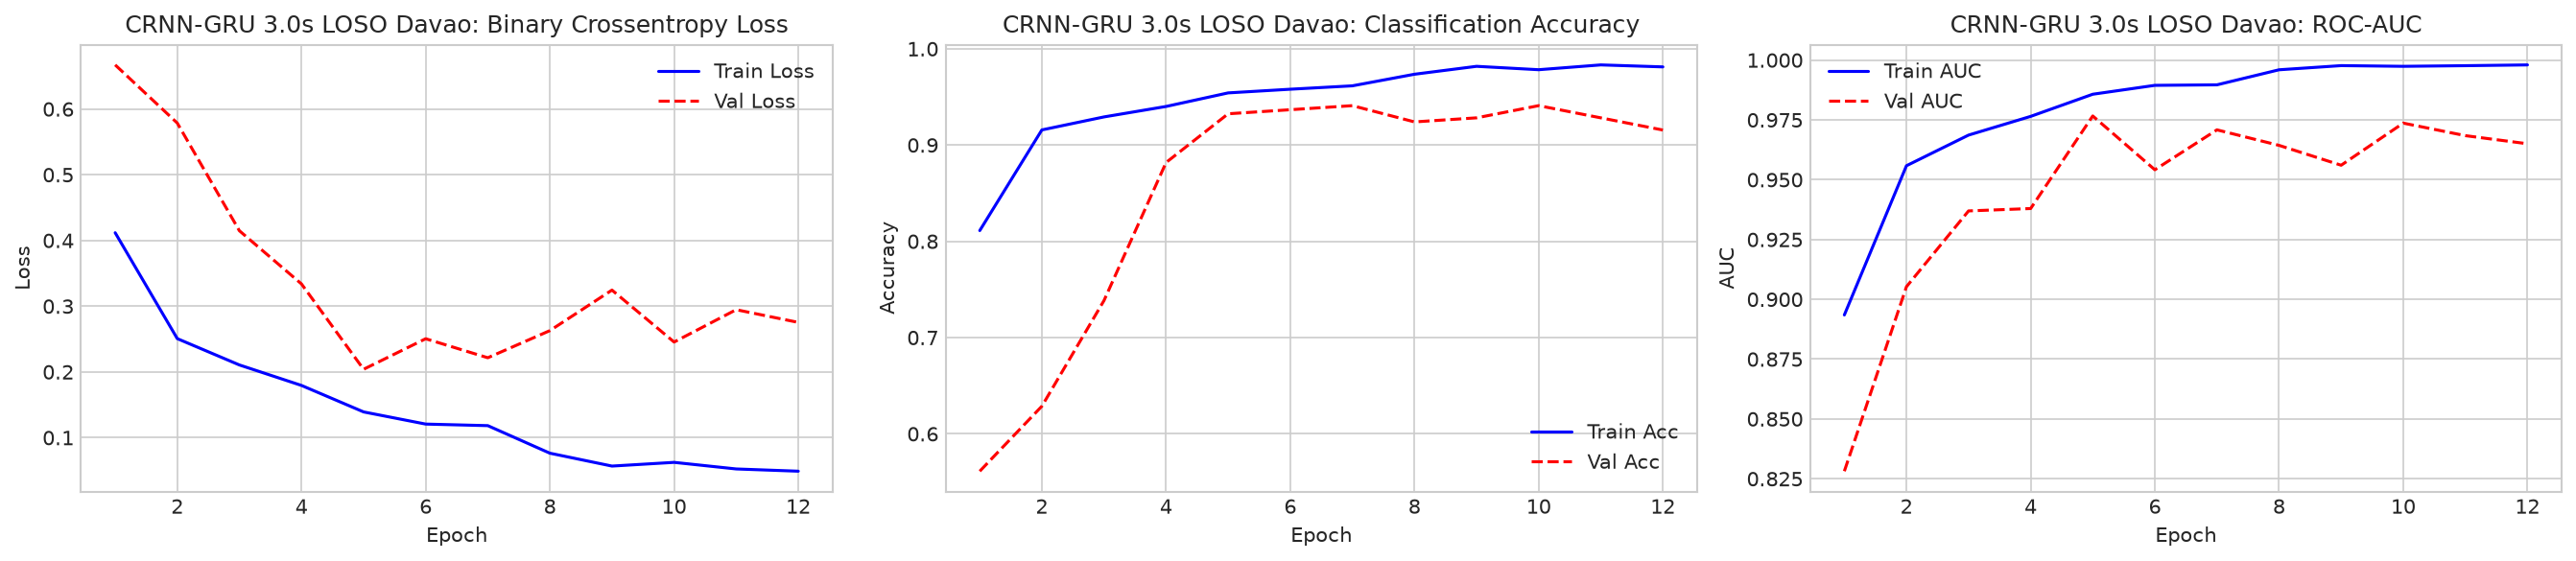

In [27]:
# Visualize training curves (3.0s LOSO Davao)
if model_3s_davao is not None and history_3s_davao_path.exists():
    history_fig_3s_davao = HISTORY_DIR / f"{NOTEBOOK_ID}-3s-loso-davao-training-history.png"
    plot_training_history(history_3s_davao, history_fig_3s_davao, title_prefix="CRNN-GRU 3.0s LOSO Davao")

#### 5.2.3 FP32 Model Evaluation (3.0s LOSO Davao)

I0000 00:00:1788972187.289096   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_80469__.7


152/155 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

I0000 00:00:1788972190.465368   84688 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81619__.7
I0000 00:00:1788972192.347969   91249 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 9468 bytes spill stores, 9408 bytes spill loads



155/155 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step
EVALUATION RESULTS: 3.0s LOSO Davao del Sur (FP32)
Accuracy:    0.8334 (83.34%)
Precision:   0.9418 (94.18%)
Recall:      0.5455 (54.55%)
F1-Score:    0.6909 (69.09%)
Specificity: 0.9825 (98.25%)
ROC-AUC:     0.9250
              precision    recall  f1-score   support

No Eagle (0)       0.81      0.98      0.89      3265
   Eagle (1)       0.94      0.55      0.69      1692

    accuracy                           0.83      4957
   macro avg       0.87      0.76      0.79      4957
weighted avg       0.85      0.83      0.82      4957

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/confusion-matrices/04-crnn-gru-model-training-3s-loso-davao-confusion-matrix.png


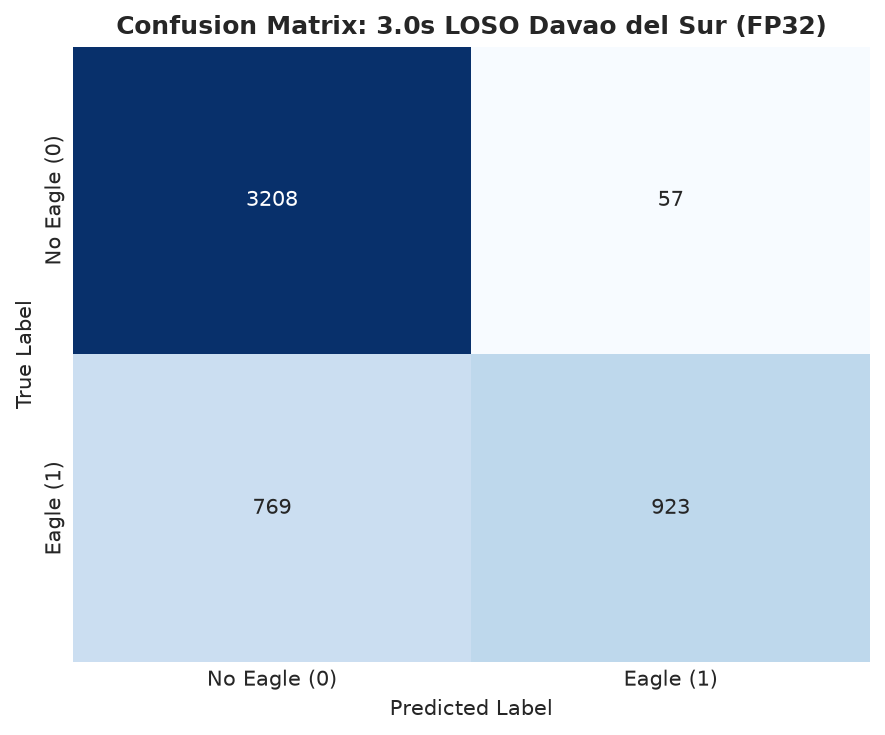

In [28]:
# Evaluate FP32 model on Davao del Sur test set (3.0s)
if model_3s_davao is not None:
    y_pred_prob_davao_3s = model_3s_davao.predict(X_test_davao_3s, batch_size=BATCH_SIZE).ravel()
    cm_fig_3s_davao = CONFUSION_DIR / f"{NOTEBOOK_ID}-3s-loso-davao-confusion-matrix.png"
    metrics_3s_davao = evaluate_predictions(y_test_davao_3s, y_pred_prob_davao_3s, "3.0s LOSO Davao del Sur (FP32)", cm_fig_3s_davao)
else:
    metrics_3s_davao = None

#### 5.2.4 INT8 Quantization and Benchmark (3.0s LOSO Davao)

In [29]:
# Full INT8 post-training quantization and benchmark (3.0s LOSO Davao, Guarded)
if model_3s_davao is not None:
    tflite_3s_davao_path = MODELS_3S_DAVAO / "crnn-gru-loso-davao-int8.tflite"
    if not tflite_3s_davao_path.exists():
        print("Converting 3.0s model to INT8 TFLite...")
        convert_to_tflite_int8(model_3s_davao, X_train_davao_3s[:300], tflite_3s_davao_path)
        print(f"Saved INT8 TFLite model to: {tflite_3s_davao_path}")
    else:
        print(f"Loading cached INT8 model from: {tflite_3s_davao_path}")

    int8_res_3s_davao = evaluate_tflite_model(tflite_3s_davao_path, X_test_davao_3s, y_test_davao_3s)
    print(f"3.0s LOSO Davao del Sur INT8 Accuracy: {int8_res_3s_davao['accuracy']*100:.2f}% | F1: {int8_res_3s_davao['f1_score']*100:.2f}%")
else:
    int8_res_3s_davao = None

Converting 3.0s model to INT8 TFLite...
INFO:tensorflow:Assets written to: /tmp/tmp981oz73h/assets


INFO:tensorflow:Assets written to: /tmp/tmp981oz73h/assets


Saved artifact at '/tmp/tmp981oz73h'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 130, 1), dtype=tf.float32, name='audio_input')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139796273343824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273334224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792608151312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273196176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792608162256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792608165328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273195792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273192912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273190032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273189840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273195984

W0000 00:00:1788972197.738871   84588 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1788972197.738886   84588 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1788972197.739009   84588 reader.cc:83] Reading SavedModel from: /tmp/tmp981oz73h
I0000 00:00:1788972197.740049   84588 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1788972197.740056   84588 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp981oz73h
I0000 00:00:1788972197.753979   84588 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1788972197.819718   84588 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp981oz73h
I0000 00:00:1788972197.846514   84588 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 107513 microseconds.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1788972207.062793   84588 flatbuffer_export.cc

Saved INT8 TFLite model to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/3-seconds/loso-davao/crnn-gru-loso-davao-int8.tflite
3.0s LOSO Davao del Sur INT8 Accuracy: 83.16% | F1: 68.64%


### 5.3. Experiment 3: Leave-One-Site-Out (LOSO) - Cotabato (3.0s)

In [30]:
# 3.0s LOSO Cotabato: Hold out entire Cotabato site
if X_all_3s is not None:
    is_test_cot_3s = (sites_all_3s == HOLDOUT_SITE_2)
    is_train_pool_cot_3s = ~is_test_cot_3s

    X_test_cot_3s = X_all_3s[is_test_cot_3s]
    y_test_cot_3s = y_all_3s[is_test_cot_3s]

    X_train_pool_cot_3s = X_all_3s[is_train_pool_cot_3s]
    y_train_pool_cot_3s = y_all_3s[is_train_pool_cot_3s]
    groups_train_pool_cot_3s = groups_all_3s[is_train_pool_cot_3s]

    gss_cot_3s = GroupShuffleSplit(n_splits=1, train_size=0.85, random_state=SEED)
    tr_c3_idx, val_c3_idx = next(gss_cot_3s.split(X_train_pool_cot_3s, y_train_pool_cot_3s, groups_train_pool_cot_3s))

    X_train_cot_3s = X_train_pool_cot_3s[tr_c3_idx]
    y_train_cot_3s = y_train_pool_cot_3s[tr_c3_idx]
    X_val_cot_3s = X_train_pool_cot_3s[val_c3_idx]
    y_val_cot_3s = y_train_pool_cot_3s[val_c3_idx]

    print(f"3.0s LOSO Cotabato Partition:")
    print(f"Train: {len(X_train_cot_3s):,} | Val: {len(X_val_cot_3s):,} | Test (Cotabato): {len(X_test_cot_3s):,}")
else:
    print("3.0s features not loaded.")

3.0s LOSO Cotabato Partition:
Train: 4,879 | Val: 330 | Test (Cotabato): 3,390


#### 5.3.1 Train or Load Model (3.0s LOSO Cotabato)

In [31]:
# Train or load 3.0s LOSO Cotabato model (Guarded, with Balanced Class Weights)
if X_all_3s is not None:
    model_3s_cot_path = MODELS_3S_COTABATO / "crnn-gru-loso-cotabato.keras"
    history_3s_cot_path = MODELS_3S_COTABATO / "training_history.json"

    class_weights_cot_3s = compute_class_weights(y_train_cot_3s)
    print(f"Balanced Class Weights (3s LOSO Cotabato): {class_weights_cot_3s}")

    if model_3s_cot_path.exists():
        print(f"Model already exists at: {model_3s_cot_path}")
        print("Loading cached model...")
        model_3s_cot = tf.keras.models.load_model(model_3s_cot_path)
        with open(history_3s_cot_path, "r") as f:
            history_3s_cot = json.load(f)
        print("3.0s LOSO Cotabato model loaded successfully from cache!")
    else:
        print("Training 3.0s LOSO Cotabato model...")
        model_3s_cot = build_crnn_gru_model(input_shape=SHAPE_3S, learning_rate=LEARNING_RATE)
        callbacks_c3 = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ModelCheckpoint(str(MODELS_3S_COTABATO / "checkpoints" / "best_model.keras"), monitor="val_loss", save_best_only=True)
        ]
        fit_c3 = model_3s_cot.fit(
            X_train_cot_3s, y_train_cot_3s,
            validation_data=(X_val_cot_3s, y_val_cot_3s),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            class_weight=class_weights_cot_3s,
            callbacks=callbacks_c3, verbose=1
        )
        model_3s_cot.save(model_3s_cot_path)
        history_3s_cot = {k: [float(v) for v in vals] for k, vals in fit_c3.history.items()}
        with open(history_3s_cot_path, "w") as f:
            json.dump(history_3s_cot, f)
else:
    model_3s_cot = None

Balanced Class Weights (3s LOSO Cotabato): {0: 0.76234375, 1: 1.4529481834425255}
Training 3.0s LOSO Cotabato model...
Epoch 1/40


I0000 00:00:1788972223.304134   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_96527__.95


151/153 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7622 - auc: 0.8359 - loss: 0.5055 - precision: 0.6316 - recall: 0.7435

I0000 00:00:1788972237.517001   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_96527__.95


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.7637 - auc: 0.8373 - loss: 0.5037 - precision: 0.6331 - recall: 0.7451

I0000 00:00:1788972254.738772   84690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_99006__.23
I0000 00:00:1788972257.075214   84691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_99006__.23
I0000 00:00:1788972258.307004   92203 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 8996 bytes spill stores, 8988 bytes spill loads



153/153 ━━━━━━━━━━━━━━━━━━━━ 46s 215ms/step - accuracy: 0.7637 - auc: 0.8373 - loss: 0.5037 - precision: 0.6331 - recall: 0.7451 - val_accuracy: 0.4636 - val_auc: 0.6974 - val_loss: 0.9910 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/40
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.8844 - auc: 0.9419 - loss: 0.3045 - precision: 0.8137 - recall: 0.8612 - val_accuracy: 0.6515 - val_auc: 0.8533 - val_loss: 0.5876 - val_precision: 1.0000 - val_recall: 0.3503
Epoch 3/40
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9156 - auc: 0.9640 - loss: 0.2356 - precision: 0.8597 - recall: 0.9017 - val_accuracy: 0.6758 - val_auc: 0.8683 - val_loss: 0.6680 - val_precision: 0.9861 - val_recall: 0.4011
Epoch 4/40
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9242 - auc: 0.9724 - loss: 0.2102 - precision: 0.8708 - recall: 0.9154 - val_accuracy: 0.7030 - val_auc: 0.9156 - val_loss: 0.7010 - val_precision: 0.9877 - val_recall: 0.4520
Epoch 5/40
153/153 ━━━━━━━━━━

#### 5.3.2 Training History Visualization (3.0s LOSO Cotabato)

Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/training-history/04-crnn-gru-model-training-3s-loso-cotabato-training-history.png


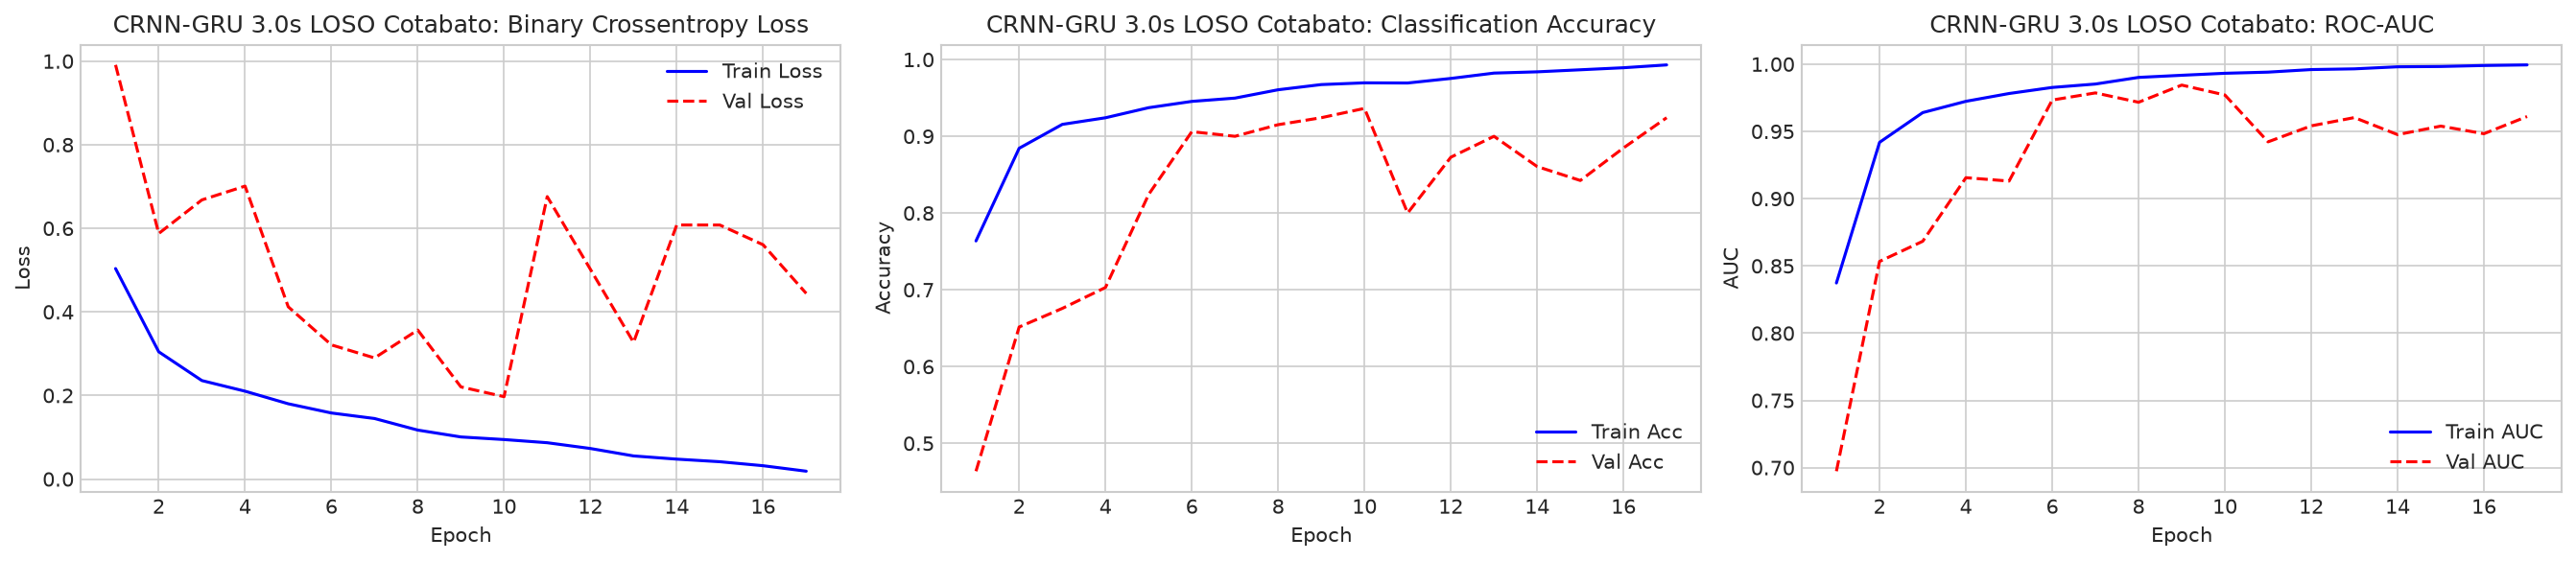

In [32]:
# Visualize training curves (3.0s LOSO Cotabato)
if model_3s_cot is not None and history_3s_cot_path.exists():
    history_fig_3s_cot = HISTORY_DIR / f"{NOTEBOOK_ID}-3s-loso-cotabato-training-history.png"
    plot_training_history(history_3s_cot, history_fig_3s_cot, title_prefix="CRNN-GRU 3.0s LOSO Cotabato")

#### 5.3.3 FP32 Model Evaluation (3.0s LOSO Cotabato)

I0000 00:00:1788972346.638641   84693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_122837__.7


103/106 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

I0000 00:00:1788972349.080508   84693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_123889__.7
I0000 00:00:1788972349.809902   93838 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15', 9092 bytes spill stores, 9192 bytes spill loads



106/106 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step
EVALUATION RESULTS: 3.0s LOSO Cotabato (FP32)
Accuracy:    0.8823 (88.23%)
Precision:   0.8420 (84.20%)
Recall:      0.8994 (89.94%)
F1-Score:    0.8697 (86.97%)
Specificity: 0.8690 (86.90%)
ROC-AUC:     0.9396
              precision    recall  f1-score   support

No Eagle (0)       0.92      0.87      0.89      1909
   Eagle (1)       0.84      0.90      0.87      1481

    accuracy                           0.88      3390
   macro avg       0.88      0.88      0.88      3390
weighted avg       0.88      0.88      0.88      3390

Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/confusion-matrices/04-crnn-gru-model-training-3s-loso-cotabato-confusion-matrix.png


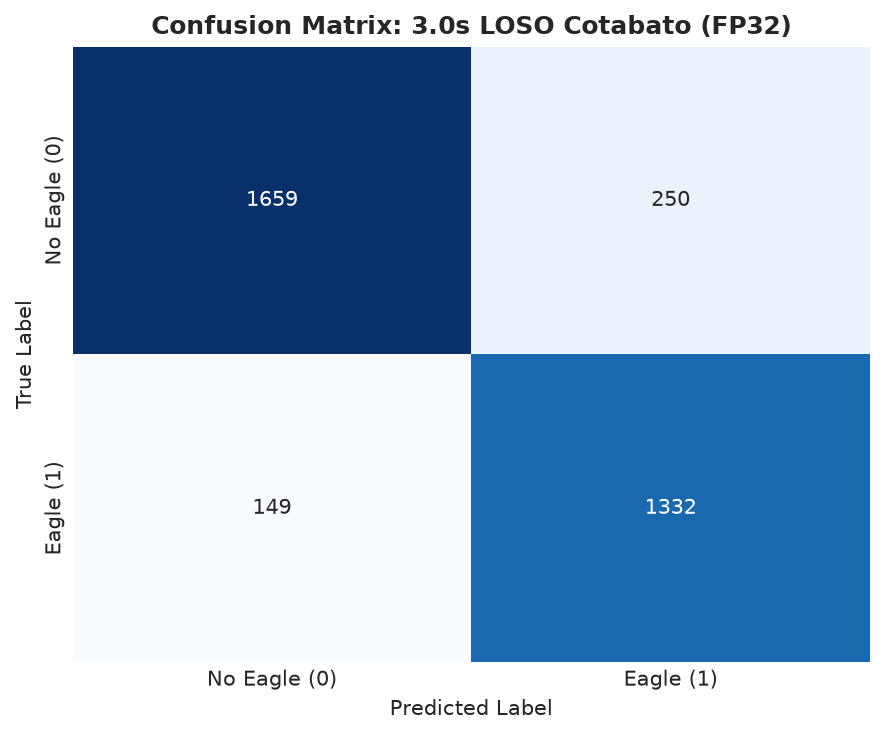

In [33]:
# Evaluate FP32 model on Cotabato test set (3.0s)
if model_3s_cot is not None:
    y_pred_prob_cot_3s = model_3s_cot.predict(X_test_cot_3s, batch_size=BATCH_SIZE).ravel()
    cm_fig_3s_cot = CONFUSION_DIR / f"{NOTEBOOK_ID}-3s-loso-cotabato-confusion-matrix.png"
    metrics_3s_cot = evaluate_predictions(y_test_cot_3s, y_pred_prob_cot_3s, "3.0s LOSO Cotabato (FP32)", cm_fig_3s_cot)
else:
    metrics_3s_cot = None

#### 5.3.4 INT8 Quantization and Benchmark (3.0s LOSO Cotabato)

In [34]:
# Full INT8 post-training quantization and benchmark (3.0s LOSO Cotabato, Guarded)
if model_3s_cot is not None:
    tflite_3s_cot_path = MODELS_3S_COTABATO / "crnn-gru-loso-cotabato-int8.tflite"
    if not tflite_3s_cot_path.exists():
        print("Converting 3.0s model to INT8 TFLite...")
        convert_to_tflite_int8(model_3s_cot, X_train_cot_3s[:300], tflite_3s_cot_path)
        print(f"Saved INT8 TFLite model to: {tflite_3s_cot_path}")
    else:
        print(f"Loading cached INT8 model from: {tflite_3s_cot_path}")

    int8_res_3s_cot = evaluate_tflite_model(tflite_3s_cot_path, X_test_cot_3s, y_test_cot_3s)
    print(f"3.0s LOSO Cotabato INT8 Accuracy: {int8_res_3s_cot['accuracy']*100:.2f}% | F1: {int8_res_3s_cot['f1_score']*100:.2f}%")
else:
    int8_res_3s_cot = None

Converting 3.0s model to INT8 TFLite...
INFO:tensorflow:Assets written to: /tmp/tmplulqb08b/assets


INFO:tensorflow:Assets written to: /tmp/tmplulqb08b/assets


Saved artifact at '/tmp/tmplulqb08b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 130, 1), dtype=tf.float32, name='audio_input')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139796273199824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139796273193296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614630864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614629136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614627984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614625680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614631056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614629520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614627216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792608153232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139792614629712

W0000 00:00:1788972355.583433   84588 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1788972355.583447   84588 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1788972355.583590   84588 reader.cc:83] Reading SavedModel from: /tmp/tmplulqb08b
I0000 00:00:1788972355.584864   84588 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1788972355.584870   84588 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmplulqb08b
I0000 00:00:1788972355.599971   84588 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1788972355.665188   84588 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmplulqb08b
I0000 00:00:1788972355.693888   84588 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 110305 microseconds.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1788972364.806697   84588 flatbuffer_export.cc

Saved INT8 TFLite model to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/models/crnn-gru/3-seconds/loso-cotabato/crnn-gru-loso-cotabato-int8.tflite
3.0s LOSO Cotabato INT8 Accuracy: 84.57% | F1: 83.74%


## 6. Multi-Scale Model Comparison: 5.0s vs. 3.0s Models

### 6.1. Comprehensive Multi-Scale Performance Comparison Table

In [35]:
# Construct comprehensive comparison DataFrame
comp_rows = []

# 5.0s Results
comp_rows.append({
    "Scale": "5.0s (216)", "Experiment": "Standard Split", "Precision": "FP32",
    "Accuracy": f"{metrics_5s_std['accuracy']*100:.2f}%", "Precision_Score": f"{metrics_5s_std['precision']*100:.2f}%",
    "Recall": f"{metrics_5s_std['recall']*100:.2f}%", "F1_Score": f"{metrics_5s_std['f1_score']*100:.2f}%",
    "ROC_AUC": f"{metrics_5s_std['roc_auc']:.4f}", "Model_Size": f"{fp32_size_kb:.0f} KB"
})
comp_rows.append({
    "Scale": "5.0s (216)", "Experiment": "Standard Split", "Precision": "INT8",
    "Accuracy": f"{int8_res_5s_std['accuracy']*100:.2f}%", "Precision_Score": f"{int8_res_5s_std['precision']*100:.2f}%",
    "Recall": f"{int8_res_5s_std['recall']*100:.2f}%", "F1_Score": f"{int8_res_5s_std['f1_score']*100:.2f}%",
    "ROC_AUC": f"{int8_res_5s_std['roc_auc']:.4f}", "Model_Size": f"{int8_size_kb:.0f} KB"
})
comp_rows.append({
    "Scale": "5.0s (216)", "Experiment": "LOSO Davao del Sur", "Precision": "FP32",
    "Accuracy": f"{metrics_5s_davao['accuracy']*100:.2f}%", "Precision_Score": f"{metrics_5s_davao['precision']*100:.2f}%",
    "Recall": f"{metrics_5s_davao['recall']*100:.2f}%", "F1_Score": f"{metrics_5s_davao['f1_score']*100:.2f}%",
    "ROC_AUC": f"{metrics_5s_davao['roc_auc']:.4f}", "Model_Size": f"{fp32_size_kb:.0f} KB"
})
comp_rows.append({
    "Scale": "5.0s (216)", "Experiment": "LOSO Davao del Sur", "Precision": "INT8",
    "Accuracy": f"{int8_res_5s_davao['accuracy']*100:.2f}%", "Precision_Score": f"{int8_res_5s_davao['precision']*100:.2f}%",
    "Recall": f"{int8_res_5s_davao['recall']*100:.2f}%", "F1_Score": f"{int8_res_5s_davao['f1_score']*100:.2f}%",
    "ROC_AUC": f"{int8_res_5s_davao['roc_auc']:.4f}", "Model_Size": f"{int8_res_5s_davao['model_size_kb']:.0f} KB"
})
comp_rows.append({
    "Scale": "5.0s (216)", "Experiment": "LOSO Cotabato", "Precision": "FP32",
    "Accuracy": f"{metrics_5s_cot['accuracy']*100:.2f}%", "Precision_Score": f"{metrics_5s_cot['precision']*100:.2f}%",
    "Recall": f"{metrics_5s_cot['recall']*100:.2f}%", "F1_Score": f"{metrics_5s_cot['f1_score']*100:.2f}%",
    "ROC_AUC": f"{metrics_5s_cot['roc_auc']:.4f}", "Model_Size": f"{fp32_size_kb:.0f} KB"
})
comp_rows.append({
    "Scale": "5.0s (216)", "Experiment": "LOSO Cotabato", "Precision": "INT8",
    "Accuracy": f"{int8_res_5s_cot['accuracy']*100:.2f}%", "Precision_Score": f"{int8_res_5s_cot['precision']*100:.2f}%",
    "Recall": f"{int8_res_5s_cot['recall']*100:.2f}%", "F1_Score": f"{int8_res_5s_cot['f1_score']*100:.2f}%",
    "ROC_AUC": f"{int8_res_5s_cot['roc_auc']:.4f}", "Model_Size": f"{int8_res_5s_cot['model_size_kb']:.0f} KB"
})

# 3.0s Results (if available)
if metrics_3s_std is not None and int8_res_3s_std is not None:
    comp_rows.append({
        "Scale": "3.0s (130)", "Experiment": "Standard Split", "Precision": "FP32",
        "Accuracy": f"{metrics_3s_std['accuracy']*100:.2f}%", "Precision_Score": f"{metrics_3s_std['precision']*100:.2f}%",
        "Recall": f"{metrics_3s_std['recall']*100:.2f}%", "F1_Score": f"{metrics_3s_std['f1_score']*100:.2f}%",
        "ROC_AUC": f"{metrics_3s_std['roc_auc']:.4f}", "Model_Size": f"{fp32_size_3s_kb:.0f} KB"
    })
    comp_rows.append({
        "Scale": "3.0s (130)", "Experiment": "Standard Split", "Precision": "INT8",
        "Accuracy": f"{int8_res_3s_std['accuracy']*100:.2f}%", "Precision_Score": f"{int8_res_3s_std['precision']*100:.2f}%",
        "Recall": f"{int8_res_3s_std['recall']*100:.2f}%", "F1_Score": f"{int8_res_3s_std['f1_score']*100:.2f}%",
        "ROC_AUC": f"{int8_res_3s_std['roc_auc']:.4f}", "Model_Size": f"{int8_size_3s_kb:.0f} KB"
    })

if metrics_3s_davao is not None and int8_res_3s_davao is not None:
    comp_rows.append({
        "Scale": "3.0s (130)", "Experiment": "LOSO Davao del Sur", "Precision": "FP32",
        "Accuracy": f"{metrics_3s_davao['accuracy']*100:.2f}%", "Precision_Score": f"{metrics_3s_davao['precision']*100:.2f}%",
        "Recall": f"{metrics_3s_davao['recall']*100:.2f}%", "F1_Score": f"{metrics_3s_davao['f1_score']*100:.2f}%",
        "ROC_AUC": f"{metrics_3s_davao['roc_auc']:.4f}", "Model_Size": f"{fp32_size_3s_kb:.0f} KB"
    })
    comp_rows.append({
        "Scale": "3.0s (130)", "Experiment": "LOSO Davao del Sur", "Precision": "INT8",
        "Accuracy": f"{int8_res_3s_davao['accuracy']*100:.2f}%", "Precision_Score": f"{int8_res_3s_davao['precision']*100:.2f}%",
        "Recall": f"{int8_res_3s_davao['recall']*100:.2f}%", "F1_Score": f"{int8_res_3s_davao['f1_score']*100:.2f}%",
        "ROC_AUC": f"{int8_res_3s_davao['roc_auc']:.4f}", "Model_Size": f"{int8_res_3s_davao['model_size_kb']:.0f} KB"
    })

if metrics_3s_cot is not None and int8_res_3s_cot is not None:
    comp_rows.append({
        "Scale": "3.0s (130)", "Experiment": "LOSO Cotabato", "Precision": "FP32",
        "Accuracy": f"{metrics_3s_cot['accuracy']*100:.2f}%", "Precision_Score": f"{metrics_3s_cot['precision']*100:.2f}%",
        "Recall": f"{metrics_3s_cot['recall']*100:.2f}%", "F1_Score": f"{metrics_3s_cot['f1_score']*100:.2f}%",
        "ROC_AUC": f"{metrics_3s_cot['roc_auc']:.4f}", "Model_Size": f"{fp32_size_3s_kb:.0f} KB"
    })
    comp_rows.append({
        "Scale": "3.0s (130)", "Experiment": "LOSO Cotabato", "Precision": "INT8",
        "Accuracy": f"{int8_res_3s_cot['accuracy']*100:.2f}%", "Precision_Score": f"{int8_res_3s_cot['precision']*100:.2f}%",
        "Recall": f"{int8_res_3s_cot['recall']*100:.2f}%", "F1_Score": f"{int8_res_3s_cot['f1_score']*100:.2f}%",
        "ROC_AUC": f"{int8_res_3s_cot['roc_auc']:.4f}", "Model_Size": f"{int8_res_3s_cot['model_size_kb']:.0f} KB"
    })

df_all_comp = pd.DataFrame(comp_rows)
print("=" * 95)
print("MULTI-SCALE CRNN-GRU COMPREHENSIVE EXPERIMENT BENCHMARK")
print("=" * 95)
print(df_all_comp.to_string(index=False))
print("=" * 95)

MULTI-SCALE CRNN-GRU COMPREHENSIVE EXPERIMENT BENCHMARK
     Scale         Experiment Precision Accuracy Precision_Score Recall F1_Score ROC_AUC Model_Size
5.0s (216)     Standard Split      FP32   90.88%          88.43% 90.54%   89.47%  0.9575    3650 KB
5.0s (216)     Standard Split      INT8   89.53%          89.44% 85.65%   87.51%  0.9459     626 KB
5.0s (216) LOSO Davao del Sur      FP32   84.97%          85.94% 76.35%   80.86%  0.9038    3650 KB
5.0s (216) LOSO Davao del Sur      INT8   82.81%          78.91% 80.07%   79.49%  0.8813     626 KB
5.0s (216)      LOSO Cotabato      FP32   80.30%          72.72% 95.30%   82.50%  0.9395    3650 KB
5.0s (216)      LOSO Cotabato      INT8   85.63%          94.77% 74.63%   83.50%  0.9172     626 KB
3.0s (130)     Standard Split      FP32   91.08%          90.56% 83.91%   87.11%  0.9519    3650 KB
3.0s (130)     Standard Split      INT8   88.85%          94.53% 73.19%   82.50%  0.9319     498 KB
3.0s (130) LOSO Davao del Sur      FP32   83

### 6.2. Comparative Performance Visualizations

Saved performance comparison figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/04-crnn-gru-model-training-5s-vs-3s-f1-comparison.png


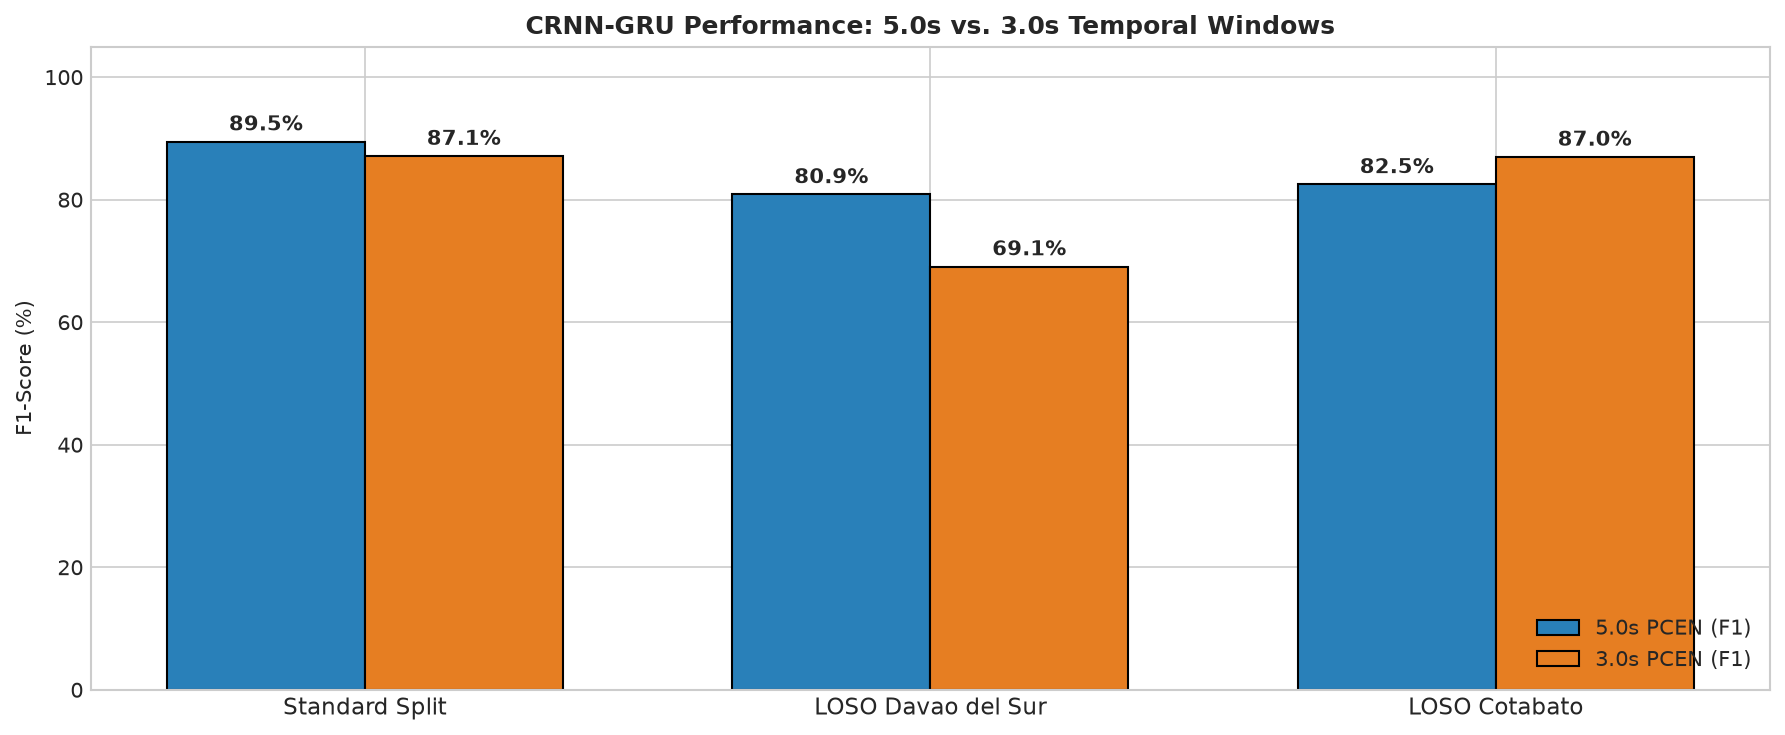

In [36]:
# Multi-panel bar chart comparing 5.0s vs 3.0s performance
fig, ax = plt.subplots(figsize=(12, 5))

# Plot F1 and Accuracy across experiments
experiments = ["Standard Split", "LOSO Davao del Sur", "LOSO Cotabato"]
f1_5s = [metrics_5s_std['f1_score']*100, metrics_5s_davao['f1_score']*100, metrics_5s_cot['f1_score']*100]

x = np.arange(len(experiments))
width = 0.35

rects1 = ax.bar(x - width/2, f1_5s, width, label="5.0s PCEN (F1)", color="#2980b9", edgecolor="black")

if metrics_3s_std is not None and metrics_3s_davao is not None and metrics_3s_cot is not None:
    f1_3s = [metrics_3s_std['f1_score']*100, metrics_3s_davao['f1_score']*100, metrics_3s_cot['f1_score']*100]
    rects2 = ax.bar(x + width/2, f1_3s, width, label="3.0s PCEN (F1)", color="#e67e22", edgecolor="black")

ax.set_title("CRNN-GRU Performance: 5.0s vs. 3.0s Temporal Windows", fontsize=12, fontweight="bold")
ax.set_ylabel("F1-Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(experiments, fontsize=11)
ax.set_ylim(0, 105)
ax.legend(loc="lower right")

for bar in rects1:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

if metrics_3s_std is not None and metrics_3s_davao is not None and metrics_3s_cot is not None:
    for bar in rects2:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
comp_plot_path = FIGURES_DIR / f"{NOTEBOOK_ID}-5s-vs-3s-f1-comparison.png"
fig.savefig(comp_plot_path, dpi=300, bbox_inches="tight")
print(f"Saved performance comparison figure to: {comp_plot_path}")
plt.show()